###Importing Libraries

In [ ]:
import pandas as pd     # Data manipulation and analysis
import numpy as np     # Numerical computing and math operations
import matplotlib.pyplot as pl     # Basic plotting and visualization
import seaborn as sns     # Statistical data visualization
from sklearn.preprocessing import LabelEncoder     # Encode categorical labels as integers
from sklearn.preprocessing import StandardScaler     # Scale features to zero mean and unit variance
from sklearn.metrics import accuracy_score, classification_report     # Evaluate model performance
from sklearn.model_selection import train_test_split     # Split dataset into training and testing sets
from sklearn.preprocessing import label_binarize     # Convert multi-class labels to binary format
from sklearn.metrics import roc_curve, auc     # Compute ROC curves and AUC scores
from sklearn.metrics import precision_score, recall_score, f1_score     # Compute precision, recall score, f1 score for accuracy
from sklearn.metrics import confusion_matrix     # Compute confusion matrix for accuracy
from sklearn.neighbors import KNeighborsClassifier     # K-Nearest Neighbors classifier
from sklearn.linear_model import LogisticRegression     # Logistic Regression classifier
from sklearn.tree import DecisionTreeClassifier     # Decision Tree classifier
from sklearn.neural_network import MLPClassifier     # Multi-layer Perceptron (Neural Network) classifier

### Dataset Collection

In [ ]:
dataset = pd.read_excel('Customer_Category_Classifier_Dataset.xlsx')

In [ ]:
print(type(dataset))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
print("Keys of given dataset:\n", dataset.keys())

Keys of given dataset:
 Index(['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1',
       'Segmentation'],
      dtype='object')


In [ ]:
# print(dataset.to_string())
print(dataset)

          ID  Gender Ever_Married  Age Graduated     Profession  \
0     462809    Male           No   22        No     Healthcare   
1     462643  Female          Yes   38       Yes       Engineer   
2     466315  Female          Yes   67       Yes       Engineer   
3     461735    Male          Yes   67       Yes         Lawyer   
4     462669  Female          Yes   40       Yes  Entertainment   
...      ...     ...          ...  ...       ...            ...   
8063  464018    Male           No   22        No            NaN   
8064  464685    Male           No   35        No      Executive   
8065  465406  Female           No   33       Yes     Healthcare   
8066  467299  Female           No   27       Yes     Healthcare   
8067  461879    Male          Yes   37       Yes      Executive   

      Work_Experience Spending_Score  Family_Size  Var_1 Segmentation  
0                 1.0            Low          4.0  Cat_4            D  
1                 NaN        Average          3.0  

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   object 
 2   Ever_Married     7928 non-null   object 
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   object 
 5   Profession       7944 non-null   object 
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   object 
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   object 
 10  Segmentation     8068 non-null   object 
dtypes: float64(2), int64(2), object(7)
memory usage: 693.5+ KB


In [ ]:
feature_names = dataset.columns.tolist()
df = pd.DataFrame(dataset, columns=feature_names[1:])

In [ ]:
numerical_data = df.select_dtypes(include='number')
numerical_features = numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:')
print(numerical_features)

There are 3 numerical features:
['Age', 'Work_Experience', 'Family_Size']


In [ ]:
categorical_data=dataset.select_dtypes(include= 'object')
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:')
print(categorical_features)

There are 7 categorical features:
['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1', 'Segmentation']


###EDA - Descriptive Analysis

In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,8068.0,43.466906,16.711696,18.0,30.0,40.0,53.0,89.0
Work_Experience,7239.0,2.641663,3.406763,0.0,0.0,1.0,4.0,14.0
Family_Size,7733.0,2.850123,1.531413,1.0,2.0,3.0,4.0,9.0


In [ ]:
categorical_data.describe().T

,count,unique,top,freq
Gender,8068,2,Male,4417
Ever_Married,7928,2,Yes,4643
Graduated,7990,2,Yes,4968
Profession,7944,9,Artist,2516
Spending_Score,8068,3,Low,4878
Var_1,7992,7,Cat_6,5238
Segmentation,8068,4,D,2268


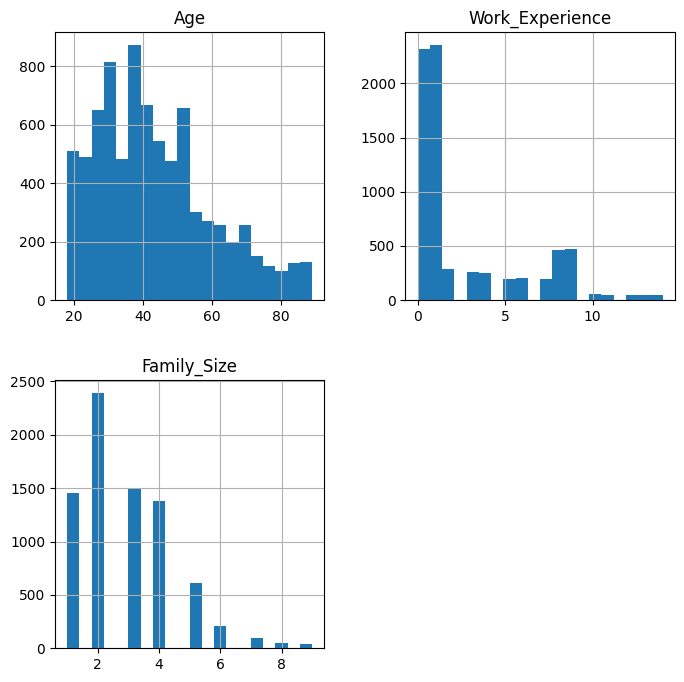

In [ ]:
numerical_data.hist(figsize=(8,8),bins=20)
pl.show()

In [ ]:
numerical_data.nunique()

,0
Age,67
Work_Experience,15
Family_Size,9


In [ ]:
categorical_data.nunique()

,0
Gender,2
Ever_Married,2
Graduated,2
Profession,9
Spending_Score,3
Var_1,7
Segmentation,4


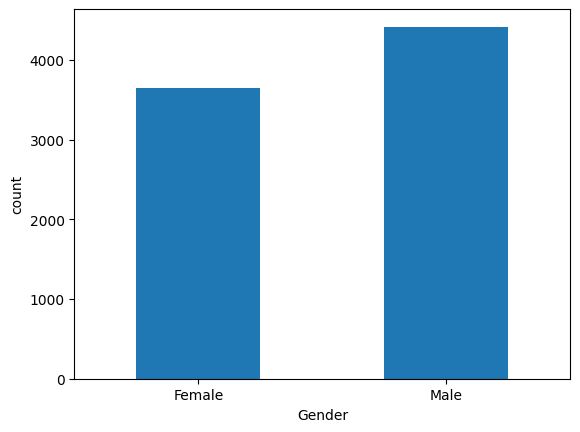

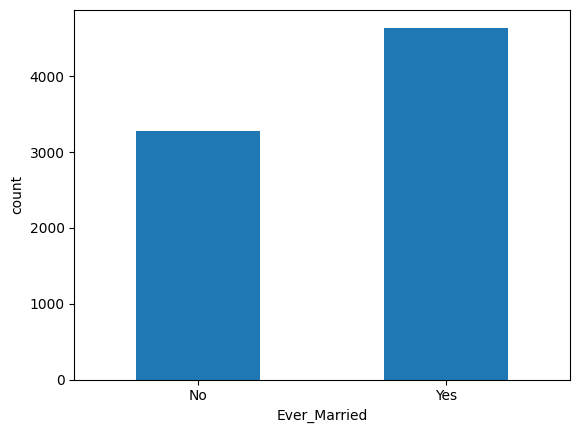

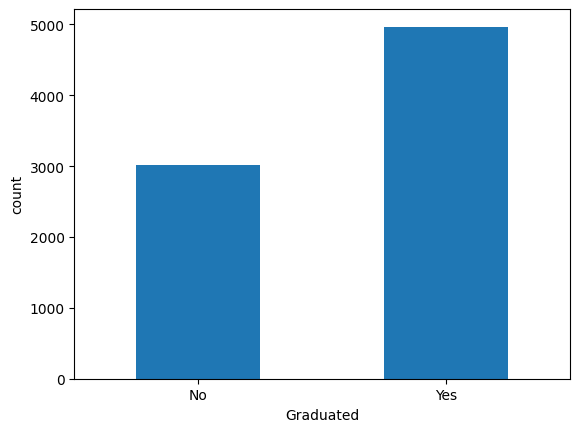

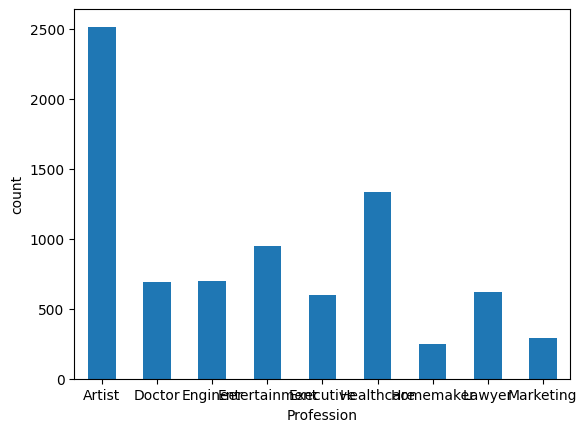

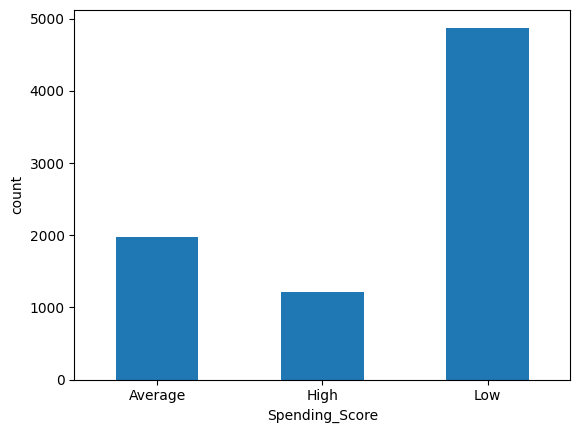

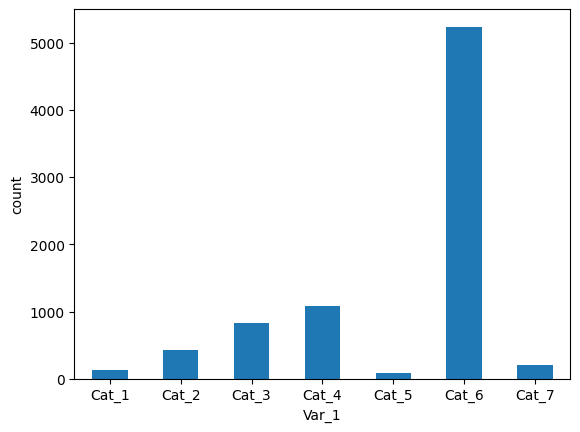

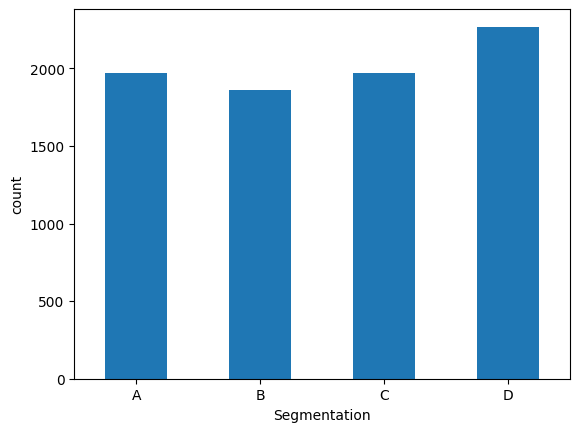

In [ ]:
for col in categorical_features:
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    pl.show()

###EDA - Correlation Analysis

In [ ]:
correlation_mat = numerical_data.corr()
correlation_mat

,Age,Work_Experience,Family_Size
Age,1.000000,-0.190789,-0.280517
Work_Experience,-0.190789,1.000000,-0.063234
Family_Size,-0.280517,-0.063234,1.000000


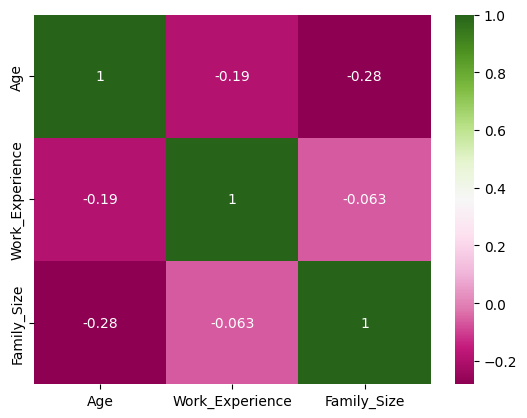

In [ ]:
sns.heatmap(correlation_mat, annot=True, cmap='PiYG')
pl.show()

###EDA - Check imbalance

In [ ]:
class_counts = dataset.groupby("Segmentation").size()

columns = ['outcome', 'count', 'percentage']
outcome = class_counts.index.tolist()
count = class_counts.values.tolist()

total = len(dataset)

percentage = [(c / total) * 100 for c in count]

imbalance_df = pd.DataFrame(list(zip(outcome, count, percentage)), columns=columns)
print(imbalance_df)

  outcome  count  percentage
0       A   1972   24.442241
1       B   1858   23.029251
2       C   1970   24.417452
3       D   2268   28.111056


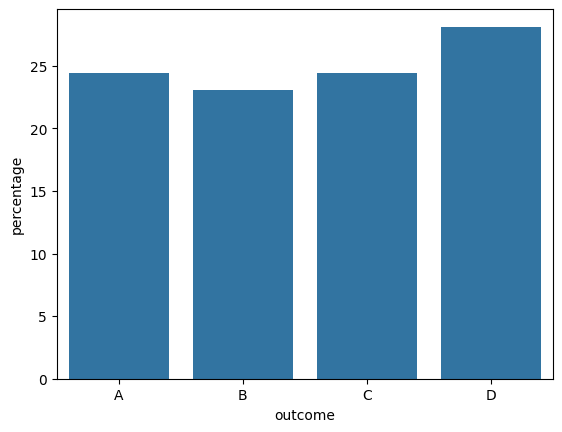

In [ ]:
sns.barplot(data=imbalance_df,x=imbalance_df['outcome'],y=imbalance_df['percentage'])
pl.show()

**Observations:**

The dataset has 4 outcome classes: A, B, C, D.

The counts are:

A → 1972 (24.44%)

B → 1858 (23.03%)

C → 1970 (24.42%)

D → 2268 (28.11%)


The difference between the smallest (B: 23.03%) and largest (D: 28.11%) class is only 5%.

This means we don't need to use Resampling Techniques.

Since no single class dominates, the model will have a better chance to learn each outcome equally well.

Therefore, the class distribution is fairly balanced, indicating that the class imbalance will not impact model training.

### Data Preproccessing

In [ ]:
volunteer = pd.read_excel('Customer_Category_Classifier_Dataset.xlsx')

In [ ]:
volunteer.shape

(8068, 11)

###Data Preproccessing : Step1 - Handling Null Values

In [ ]:
df1 = dataset.copy()

*   Removing columns


In [ ]:
column_null_values = dataset.isnull().sum()
print("Null values per column:\n", column_null_values)
# Not enough Null values to remove a column

Null values per column:
 ID                   0
Gender               0
Ever_Married       140
Age                  0
Graduated           78
Profession         124
Work_Experience    829
Spending_Score       0
Family_Size        335
Var_1               76
Segmentation         0
dtype: int64




*   Removing rows


In [ ]:
row_null_values = dataset.isnull().sum(axis=1)
print("Null values per row:\n", row_null_values)

Null values per row:
 0       0
1       1
2       0
3       0
4       1
       ..
8063    1
8064    0
8065    0
8066    0
8067    0
Length: 8068, dtype: int64


In [ ]:
# rows_nulls -- rows with number of Null values > 6 (out of 11), removable
rows_nulls = dataset[row_null_values > 6]
print("Rows with more than 6 Null values:", len(rows_nulls))
# Not enough Null values to remove a row

Rows with more than 6 Null values: 0


In [ ]:
# rows_nulls -- rows with number of Null values = 4 (out of 11), removable
rows_nulls = dataset[row_null_values == 4]
print("Rows with 4 Null values:", len(rows_nulls))

Rows with 4 Null values: 1


In [ ]:
nan_rows = df1[df1["Ever_Married"].isna()]
df1 = df1.drop(nan_rows.index)
print(f"{len(nan_rows)} rows with nan values of Ever_Married dropped")

140 rows with nan values of Ever_Married dropped


In [ ]:
nan_rows = df1[df1["Graduated"].isna()]
df1 = df1.drop(nan_rows.index)
print(f"{len(nan_rows)} rows with nan values of Graduated dropped")

74 rows with nan values of Graduated dropped


In [ ]:
print("Shape before dropping row:", dataset.shape)
del_row = dataset[dataset.isnull().sum(axis=1) == 4]
# print(del_row)
del_row_index = df1[df1.isnull().sum(axis=1) == 4].index
df1.drop(index = del_row_index, inplace=True)
print("Shape after dropping row:", df1.shape)

Shape before dropping row: (8068, 11)
Shape after dropping row: (7854, 11)




*   Data imputing


In [ ]:
nan_count = df1["Age"].isnull().sum()
print("Number of NaN values in 'Age':", nan_count)
nan_count = df1["Work_Experience"].isnull().sum()
print("Number of NaN values in 'Work_Experience':", nan_count)
nan_count = df1["Family_Size"].isnull().sum()
print("Number of NaN values in 'Family_Size':", nan_count)
nan_count = df1["Var_1"].isnull().sum()
print("Number of NaN values in 'Var_1':", nan_count)

Number of NaN values in 'Age': 0
Number of NaN values in 'Work_Experience': 794
Number of NaN values in 'Family_Size': 316
Number of NaN values in 'Var_1': 75


In [ ]:
df2 = df1.copy()

Using mean value range

In [ ]:
nan_count = df2[df2["Work_Experience"].isnull()]
print("Rows with NaN before replacement:", len(nan_count))
nan_rows = nan_count.loc[nan_count.index, ["ID", "Work_Experience"]]
print("Number of NaN values in 'Work_Experience':\n", nan_rows)

Rows with NaN before replacement: 794
Number of NaN values in 'Work_Experience':
           ID  Work_Experience
1     462643              NaN
4     462669              NaN
13    459573              NaN
39    467442              NaN
45    463156              NaN
...      ...              ...
8020  465278              NaN
8029  462516              NaN
8040  467165              NaN
8047  462396              NaN
8049  461292              NaN

[794 rows x 2 columns]


In [ ]:
import random

In [ ]:
mean_val = int(df2["Work_Experience"].mean())
low, high = mean_val - 2, mean_val + 2
def deterministic_random(idx, low, high, seed=42):
    rng = np.random.RandomState(seed + idx)
    return rng.randint(low, high + 1)
df2["Work_Experience"] = df2["Work_Experience"].where(
    ~df2["Work_Experience"].isna(),
    [deterministic_random(idx, low, high) for idx in df2.index])
df2["Work_Experience"] = df2["Work_Experience"].astype(int)

In [ ]:
filled_rows = df2.loc[nan_count.index, ["ID", "Work_Experience"]]
print("\nRows after replacement:")
print(filled_rows)


Rows after replacement:
          ID  Work_Experience
1     462643                4
4     462669                0
13    459573                2
39    467442                3
45    463156                3
...      ...              ...
8020  465278                1
8029  462516                0
8040  467165                1
8047  462396                3
8049  461292                2

[794 rows x 2 columns]


In [ ]:
nan_count = df2[df2["Work_Experience"].isnull()]
print("Rows with NaN after replacement:", len(nan_count))

Rows with NaN after replacement: 0


Using fixed value

In [ ]:
nan_count = df2[df2["Family_Size"].isnull()]
print("Rows with NaN before replacement:", len(nan_count))

fixed_val = 3
df2["Family_Size"].fillna(fixed_val, inplace=True)
df2["Family_Size"] = df2["Family_Size"].astype(int)

filled_rows = df2.loc[nan_count.index, ["ID", "Family_Size"]]
print("\nRows after replacement:")
print(filled_rows)

nan_count = df2[df2["Family_Size"].isnull()]
print("Rows with NaN after replacement:", len(nan_count))

Rows with NaN before replacement: 316

Rows after replacement:
          ID  Family_Size
12    461230            3
33    467010            3
59    460881            3
112   467758            3
126   466295            3
...      ...          ...
7926  467133            3
7937  460019            3
7992  467574            3
8017  461758            3
8024  467153            3

[316 rows x 2 columns]
Rows with NaN after replacement: 0


/tmp/ipython-input-2795691668.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2["Family_Size"].fillna(fixed_val, inplace=True)


Categorical encoding

In [ ]:
nan_count = df2[df2["Var_1"].isnull()]
print("Rows with NaN before replacement:", len(nan_count))

df2["Var_1"].fillna("Missing", inplace=True)

filled_rows = df2.loc[nan_count.index, ["ID", "Var_1"]]
print("\nRows after replacement:")
print(filled_rows)

nan_count = df2[df2["Var_1"].isnull()]
print("Rows with NaN after replacement:", len(nan_count))

Rows with NaN before replacement: 75

Rows after replacement:
          ID    Var_1
43    466006  Missing
163   463595  Missing
186   459576  Missing
231   463467  Missing
233   461282  Missing
...      ...      ...
7548  466477  Missing
7715  459724  Missing
7761  462935  Missing
7913  467544  Missing
7991  462092  Missing

[75 rows x 2 columns]
Rows with NaN after replacement: 0


/tmp/ipython-input-1605590932.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2["Var_1"].fillna("Missing", inplace=True)


In [ ]:
nan_count = df2[df2["Profession"].isnull()]
print("Rows with NaN before replacement:", len(nan_count))

df2["Profession"].fillna("Missing", inplace=True)

filled_rows = df2.loc[nan_count.index, ["ID", "Profession"]]
print("\nRows after replacement:")
print(filled_rows)

nan_count = df2[df2["Profession"].isnull()]
print("Rows with NaN after replacement:", len(nan_count))

Rows with NaN before replacement: 113

Rows after replacement:
          ID Profession
79    466567    Missing
118   465827    Missing
219   465837    Missing
237   467252    Missing
437   461410    Missing
...      ...        ...
7725  467357    Missing
7870  462301    Missing
7899  464548    Missing
7935  464977    Missing
8063  464018    Missing

[113 rows x 2 columns]
Rows with NaN after replacement: 0


/tmp/ipython-input-3757004501.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2["Profession"].fillna("Missing", inplace=True)


###Data Preproccessing : Step2 - Feature Encoding

In [ ]:
df3 = df2.copy()
df3.head()
df3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7854 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ID               7854 non-null   int64 
 1   Gender           7854 non-null   object
 2   Ever_Married     7854 non-null   object
 3   Age              7854 non-null   int64 
 4   Graduated        7854 non-null   object
 5   Profession       7854 non-null   object
 6   Work_Experience  7854 non-null   int64 
 7   Spending_Score   7854 non-null   object
 8   Family_Size      7854 non-null   int64 
 9   Var_1            7854 non-null   object
 10  Segmentation     7854 non-null   object
dtypes: int64(4), object(7)
memory usage: 994.4+ KB


In [ ]:
unique_counts=categorical_data.nunique()
print(unique_counts)

Gender            2
Ever_Married      2
Graduated         2
Profession        9
Spending_Score    3
Var_1             7
Segmentation      4
dtype: int64




*   Label Encoding



In [ ]:
enc = LabelEncoder()

In [ ]:
df3['Gender_enc'] = enc.fit_transform(df3['Gender'])
print(df3[['Gender', 'Gender_enc']].head())
df3['Gender'] = df3['Gender_enc']
df3 = df3.drop(['Gender_enc'], axis = 1)

   Gender  Gender_enc
0    Male           1
1  Female           0
2  Female           0
3    Male           1
4  Female           0


In [ ]:
df3['Ever_Married_enc'] = enc.fit_transform(df3['Ever_Married'])
print(df3[['Ever_Married', 'Ever_Married_enc']].head())
df3['Ever_Married'] = df3['Ever_Married_enc']
df3 = df3.drop(['Ever_Married_enc'], axis = 1)

  Ever_Married  Ever_Married_enc
0           No                 0
1          Yes                 1
2          Yes                 1
3          Yes                 1
4          Yes                 1


In [ ]:
df3['Graduated_enc'] = enc.fit_transform(df3['Graduated'])
print(df3[['Graduated', 'Graduated_enc']].head())
df3['Graduated'] = df3['Graduated_enc']
df3 = df3.drop(['Graduated_enc'], axis = 1)

  Graduated  Graduated_enc
0        No              0
1       Yes              1
2       Yes              1
3       Yes              1
4       Yes              1


In [ ]:
df3['Spending_Score_enc'] = df3['Spending_Score'].map({'Low':0,'Average':1,'High':2})
print(df3[['Spending_Score', 'Spending_Score_enc']].head())
df3['Spending_Score'] = df3['Spending_Score_enc']
df3 = df3.drop(['Spending_Score_enc'], axis = 1)

  Spending_Score  Spending_Score_enc
0            Low                   0
1        Average                   1
2            Low                   0
3           High                   2
4           High                   2


In [ ]:
df3['Var_1'].unique()

array(['Cat_4', 'Cat_6', 'Cat_7', 'Cat_3', 'Cat_1', 'Cat_2', 'Missing',
       'Cat_5'], dtype=object)

In [ ]:
df3['Var1_enc'] = enc.fit_transform(df3['Var_1'])
print(df3[['Var_1', 'Var1_enc']].tail(10))
df3['Var_1'] = df3['Var1_enc']
df3 = df3.drop(['Var1_enc'], axis = 1)

      Var_1  Var1_enc
8058  Cat_3         2
8059  Cat_6         5
8060  Cat_6         5
8061  Cat_6         5
8062  Cat_6         5
8063  Cat_1         0
8064  Cat_4         3
8065  Cat_6         5
8066  Cat_6         5
8067  Cat_4         3


In [ ]:
print(df3)

          ID  Gender  Ever_Married  Age  Graduated     Profession  \
0     462809       1             0   22          0     Healthcare   
1     462643       0             1   38          1       Engineer   
2     466315       0             1   67          1       Engineer   
3     461735       1             1   67          1         Lawyer   
4     462669       0             1   40          1  Entertainment   
...      ...     ...           ...  ...        ...            ...   
8063  464018       1             0   22          0        Missing   
8064  464685       1             0   35          0      Executive   
8065  465406       0             0   33          1     Healthcare   
8066  467299       0             0   27          1     Healthcare   
8067  461879       1             1   37          1      Executive   

      Work_Experience  Spending_Score  Family_Size  Var_1 Segmentation  
0                   1               0            4      3            D  
1                   4    



*   One-hot Encoding



In [ ]:
df4 = df3.copy()

In [ ]:
df4['Profession'].unique()

array(['Healthcare', 'Engineer', 'Lawyer', 'Entertainment', 'Artist',
       'Executive', 'Doctor', 'Homemaker', 'Marketing', 'Missing'],
      dtype=object)

In [ ]:
Profession_enc = pd.get_dummies(df4['Profession'])

Profession_enc.head()
df4 = pd.get_dummies(df4, columns=['Profession'])
df4.head()

,ID,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Profession_Artist,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Profession_Missing
0,462809,1,0,22,0,1,0,4,3,D,False,False,False,False,False,True,False,False,False,False
1,462643,0,1,38,1,4,1,3,3,A,False,False,True,False,False,False,False,False,False,False
2,466315,0,1,67,1,1,0,1,5,B,False,False,True,False,False,False,False,False,False,False
3,461735,1,1,67,1,0,2,2,5,B,False,False,False,False,False,False,False,True,False,False
4,462669,0,1,40,1,0,2,6,5,A,False,False,False,True,False,False,False,False,False,False


In [ ]:
df4.shape

(7854, 20)

In [ ]:
# using One Hot Encoding in the "Profession" column results in 19 columns in the dataset
# no overlapping data
# for convenience, using label encoding for "Profession"

In [ ]:
df3['Profession_enc'] = enc.fit_transform(df3['Profession'])
print(df3[['Profession_enc', 'Profession']].tail(10))
df3['Profession'] = df3['Profession_enc']
df3 = df3.drop(['Profession_enc'], axis = 1)

      Profession_enc     Profession
8058               3  Entertainment
8059               5     Healthcare
8060               0         Artist
8061               0         Artist
8062               0         Artist
8063               9        Missing
8064               4      Executive
8065               5     Healthcare
8066               5     Healthcare
8067               4      Executive


In [ ]:
print(df3)

          ID  Gender  Ever_Married  Age  Graduated  Profession  \
0     462809       1             0   22          0           5   
1     462643       0             1   38          1           2   
2     466315       0             1   67          1           2   
3     461735       1             1   67          1           7   
4     462669       0             1   40          1           3   
...      ...     ...           ...  ...        ...         ...   
8063  464018       1             0   22          0           9   
8064  464685       1             0   35          0           4   
8065  465406       0             0   33          1           5   
8066  467299       0             0   27          1           5   
8067  461879       1             1   37          1           4   

      Work_Experience  Spending_Score  Family_Size  Var_1 Segmentation  
0                   1               0            4      3            D  
1                   4               1            3      3    

In [ ]:
column_null_values = df3.isnull().sum()
print("Null values per column:\n", column_null_values)

Null values per column:
 ID                 0
Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64


### Data Preproccessing : Step3 - Feature Selection

In [ ]:
df4 = df3.copy()

In [ ]:
feature_names = df4.columns.tolist()
print("Feature names:", feature_names)

Feature names: ['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']


In [ ]:
data = df4.values
print("Data shape:", data.shape)

Data shape: (7854, 11)


In [ ]:
df4 = pd.DataFrame(data, columns=feature_names)

In [ ]:
df4 = df4.drop(["Segmentation"], axis=1)
# print(df4)
# dropping categorical column

In [ ]:
df4.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,462809,1,0,22,0,5,1,0,4,3
1,462643,0,1,38,1,2,4,1,3,3
2,466315,0,1,67,1,2,1,0,1,5
3,461735,1,1,67,1,7,0,2,2,5
4,462669,0,1,40,1,3,0,2,6,5


In [ ]:
correlate = df4.corr()
correlate

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
ID,1.000000,0.006729,0.022405,-0.001073,-0.008859,-0.005508,-0.023353,0.010387,0.008520,-0.003858
Gender,0.006729,1.000000,0.116184,0.026665,-0.036475,0.023423,-0.052640,0.061546,0.055429,0.022864
Ever_Married,0.022405,0.116184,1.000000,0.567250,0.196893,-0.133948,-0.090935,0.616524,-0.077637,0.083515
Age,-0.001073,0.026665,0.567250,1.000000,0.236786,0.039656,-0.176576,0.420565,-0.274640,0.165704
Graduated,-0.008859,-0.036475,0.196893,0.236786,1.000000,-0.293458,0.034737,0.107904,-0.229484,0.118183
Profession,-0.005508,0.023423,-0.133948,0.039656,-0.293458,1.000000,-0.027895,0.001526,0.082119,-0.037044
Work_Experience,-0.023353,-0.052640,-0.090935,-0.176576,0.034737,-0.027895,1.000000,-0.073970,-0.065417,0.026378
Spending_Score,0.010387,0.061546,0.616524,0.420565,0.107904,0.001526,-0.073970,1.000000,0.091170,0.080614
Family_Size,0.008520,0.055429,-0.077637,-0.274640,-0.229484,0.082119,-0.065417,0.091170,1.000000,-0.141427
Var_1,-0.003858,0.022864,0.083515,0.165704,0.118183,-0.037044,0.026378,0.080614,-0.141427,1.000000


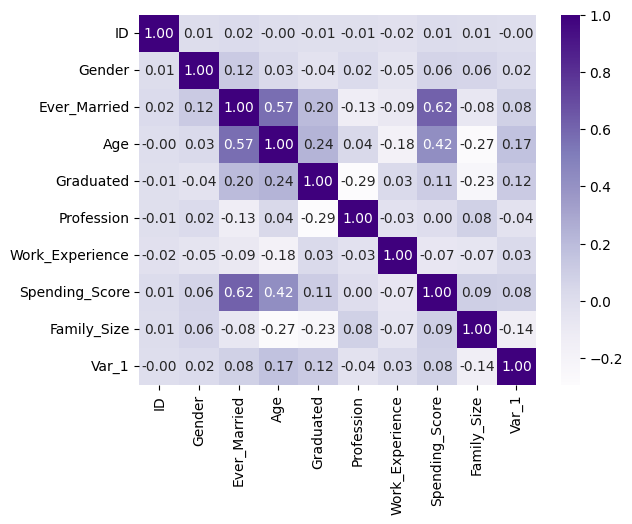

In [ ]:
sns.heatmap(correlate, cmap="Purples", annot=True, fmt=".2f")
pl.show()

In [ ]:
# highly corelated features give almost similar information, no new information, hence can be removed
# features with no corelation are independent, provides new information, corelation-->0
# here, the features are not highly correlated
# so, not dropping any column

### Data Preproccessing : Step4 - Removing Outliers

In [ ]:
df5 = df3.copy()

In [ ]:
feature_names = df5.columns.tolist()
print(feature_names)

['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']


Applying Inter Quartile Range - IQR

In [ ]:
outliers = {}
for col in feature_names[:len(feature_names)-1]:
    Q1 = df4[col].quantile(0.25)
    Q3 = df4[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers[col] = df4[(df4[col] < lower) | (df4[col] > upper)]

In [ ]:
for col in feature_names[:len(feature_names)-1]:
  print(f"Number of outliers in {col}:", len(outliers[col]))

Number of outliers in ID: 0
Number of outliers in Gender: 0
Number of outliers in Ever_Married: 0
Number of outliers in Age: 97
Number of outliers in Graduated: 0
Number of outliers in Profession: 0
Number of outliers in Work_Experience: 186
Number of outliers in Spending_Score: 0
Number of outliers in Family_Size: 90
Number of outliers in Var_1: 0


In [ ]:
print(outliers['Age'][['ID', 'Age']])
outliers_id = outliers['Age']['ID']
df5 = df5[~df5['ID'].isin(outliers_id)]
print("\nAge outlier columns dropped")

          ID Age
312   467714  89
386   462149  89
449   461621  87
639   467098  87
682   465264  88
...      ...  ..
7655  465221  88
7657  464157  88
7673  460939  87
7711  460810  89
7806  460935  87

[97 rows x 2 columns]

Age outlier columns dropped


In [ ]:
print(outliers['Work_Experience'][['ID', 'Work_Experience']])
outliers_id = outliers['Work_Experience']['ID']
df5 = df5[~df5['ID'].isin(outliers_id)]
print("\nWork_Experience outlier columns dropped")

          ID Work_Experience
20    466084              12
22    465602              13
41    464590              14
54    462110              14
173   464866              11
...      ...             ...
7626  463655              13
7661  462301              12
7780  465597              14
7816  465501              13
7830  462049              14

[186 rows x 2 columns]

Work_Experience outlier columns dropped


In [ ]:
print(outliers['Family_Size'][['ID', 'Family_Size']])
outliers_id = outliers['Family_Size']['ID']
df5 = df5[~df5['ID'].isin(outliers_id)]
print("\nFamily_Size outlier columns dropped")

          ID Family_Size
25    467604           8
147   464972           9
198   464863           8
284   459471           8
335   462391           8
...      ...         ...
7568  464855           9
7591  460608           8
7688  464675           9
7691  462751           9
7783  463940           8

[90 rows x 2 columns]

Family_Size outlier columns dropped


In [ ]:
print(df5)

          ID  Gender  Ever_Married  Age  Graduated  Profession  \
0     462809       1             0   22          0           5   
1     462643       0             1   38          1           2   
2     466315       0             1   67          1           2   
3     461735       1             1   67          1           7   
4     462669       0             1   40          1           3   
...      ...     ...           ...  ...        ...         ...   
8063  464018       1             0   22          0           9   
8064  464685       1             0   35          0           4   
8065  465406       0             0   33          1           5   
8066  467299       0             0   27          1           5   
8067  461879       1             1   37          1           4   

      Work_Experience  Spending_Score  Family_Size  Var_1 Segmentation  
0                   1               0            4      3            D  
1                   4               1            3      3    

In [ ]:
class_counts = df5.groupby("Segmentation").size()

columns = ['outcome', 'count', 'percentage']
outcome = class_counts.index.tolist()
count = class_counts.values.tolist()

total = len(df5)
percentage = [(c / total) * 100 for c in count]

imbalance_df = pd.DataFrame(list(zip(outcome, count, percentage)), columns=columns)
print(imbalance_df)

  outcome  count  percentage
0       A   1796   23.988246
1       B   1748   23.347135
2       C   1860   24.843061
3       D   2083   27.821557


###Data Splitting

In [ ]:
df6 = df5.copy()

In [ ]:
print(df6.shape)

(7487, 11)


In [ ]:
x = df6.drop(columns=["ID","Segmentation"], axis=1)
y = df6["Segmentation"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state=0, stratify = y)

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (5240, 9)
y_train shape: (5240,)


In [ ]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (2247, 9)
y_test shape: (2247,)


###Data Visualization

array([[<Axes: xlabel='Age', ylabel='Age'>,
        <Axes: xlabel='Profession', ylabel='Age'>,
        <Axes: xlabel='Work_Experience', ylabel='Age'>,
        <Axes: xlabel='Family_Size', ylabel='Age'>,
        <Axes: xlabel='Var_1', ylabel='Age'>],
       [<Axes: xlabel='Age', ylabel='Profession'>,
        <Axes: xlabel='Profession', ylabel='Profession'>,
        <Axes: xlabel='Work_Experience', ylabel='Profession'>,
        <Axes: xlabel='Family_Size', ylabel='Profession'>,
        <Axes: xlabel='Var_1', ylabel='Profession'>],
       [<Axes: xlabel='Age', ylabel='Work_Experience'>,
        <Axes: xlabel='Profession', ylabel='Work_Experience'>,
        <Axes: xlabel='Work_Experience', ylabel='Work_Experience'>,
        <Axes: xlabel='Family_Size', ylabel='Work_Experience'>,
        <Axes: xlabel='Var_1', ylabel='Work_Experience'>],
       [<Axes: xlabel='Age', ylabel='Family_Size'>,
        <Axes: xlabel='Profession', ylabel='Family_Size'>,
        <Axes: xlabel='Work_Experience', yla

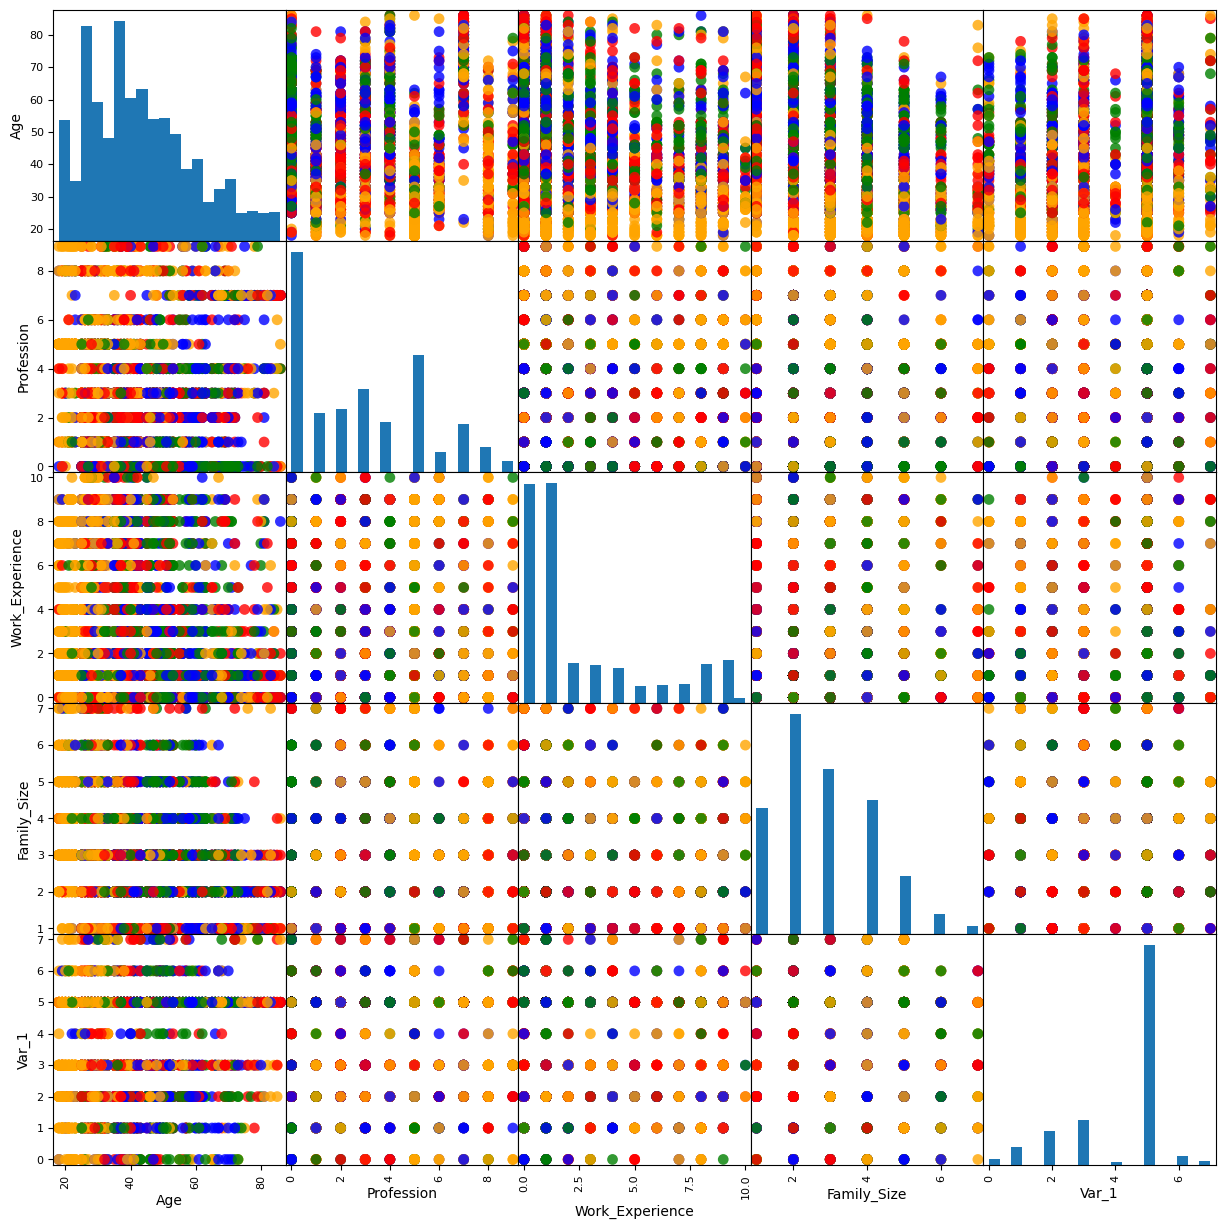

In [ ]:
selected_feature = ['Age', 'Profession', 'Work_Experience', 'Family_Size', 'Var_1']
df7 = pd.DataFrame(X_train, columns=selected_feature)
color_map = {'A': 'red', 'B': 'blue', 'C': 'green', 'D': 'orange'}
y_colors = y_train.map(color_map)

pd.plotting.scatter_matrix(
    df7,
    c=y_colors,
    figsize=(15, 15),
    marker='o',
    hist_kwds={'bins': 20},
    s=60,
    alpha=0.8
)

###Feature Scaling

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [ ]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("per-feature minimum before scaling:\n {}".format(X_train.min(axis=0)))
print("per-feature maximum before scaling:\n {}".format(X_train.max(axis=0)))

per-feature minimum before scaling:
 Gender              0
Ever_Married        0
Age                18
Graduated           0
Profession          0
Work_Experience     0
Spending_Score      0
Family_Size         1
Var_1               0
dtype: int64
per-feature maximum before scaling:
 Gender              1
Ever_Married        1
Age                86
Graduated           1
Profession          9
Work_Experience    10
Spending_Score      2
Family_Size         7
Var_1               7
dtype: int64


In [ ]:
print("per-feature minimum after scaling:\n {}".format(X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(X_train_scaled.max(axis=0)))

per-feature minimum after scaling:
 [-1.09959367 -1.19506244 -1.56383641 -1.28627704 -1.08441505 -0.80228768
 -0.74048934 -1.32545341 -2.89759612]
per-feature maximum after scaling:
 [0.90942684 0.83677636 2.65725434 0.7774375  2.36128052 2.63065976
 1.97101599 3.0395047  1.9555466 ]


###Model Training - KNN

In [ ]:
knn = KNeighborsClassifier(n_neighbors=30)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=30)

###Model Training - Neural Network

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [ ]:
le = LabelEncoder()
Y_train_numeric = le.fit_transform(y_train)
Y_test_numeric = le.transform(y_test)

In [ ]:
n_features = X_train.shape[1]
n_classes = len(np.unique(Y_train_numeric))

model = Sequential([
    Dense(64, activation='relu', input_shape=(n_features,)),
    Dense(32, activation='relu'),
    Dense(n_classes, activation='softmax')
])

model.compile(
    optimizer=Adam(0.001),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

history = model.fit(X_train_scaled, Y_train_numeric, epochs=50, batch_size=64)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3391 - loss: 1.3607
Epoch 2/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4938 - loss: 1.1442
Epoch 3/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5176 - loss: 1.0983
Epoch 4/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5173 - loss: 1.1002
Epoch 5/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5156 - loss: 1.0812
Epoch 6/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5324 - loss: 1.0697
Epoch 7/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5417 - loss: 1.0617
Epoch 8/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5338 - loss: 1.0708
Epoch 9/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5331 - loss: 1.0744
Epoch 10/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5319 - loss: 1.0689
Epoch 11/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5379 - loss: 1.0450
Epoch 12/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5517 - loss: 1.0317


###Model Training - Logistic Regression

In [ ]:
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=500)
model.fit(X_train_scaled, Y_train_numeric)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=500, multi_class='multinomial')

###Model Training - Decision Tree

In [ ]:
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    random_state=42
)
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

###Model Prediction

In [ ]:
y_pred1 = knn.predict(X_test_scaled)
print("First 100 test set predictions using KNN:\n", y_pred1[:100])

First 100 test set predictions using KNN:
 ['C' 'C' 'B' 'D' 'D' 'B' 'A' 'D' 'C' 'C' 'A' 'C' 'C' 'C' 'D' 'A' 'D' 'A'
 'B' 'D' 'A' 'C' 'D' 'B' 'A' 'D' 'B' 'C' 'D' 'B' 'B' 'A' 'D' 'D' 'A' 'A'
 'B' 'C' 'D' 'B' 'D' 'B' 'A' 'B' 'A' 'C' 'A' 'B' 'A' 'A' 'B' 'B' 'C' 'B'
 'D' 'A' 'D' 'A' 'B' 'D' 'C' 'A' 'C' 'D' 'D' 'B' 'A' 'A' 'A' 'D' 'A' 'D'
 'A' 'D' 'D' 'A' 'B' 'D' 'A' 'D' 'D' 'C' 'C' 'A' 'A' 'D' 'C' 'C' 'B' 'A'
 'C' 'B' 'A' 'B' 'A' 'A' 'A' 'B' 'C' 'B']


In [ ]:
y_pred_numeric = model.predict(X_test_scaled)
y_pred2 = le.inverse_transform(y_pred_numeric)
print("First 100 test set predictions using Neural Network:\n", y_pred2[:100])

First 100 test set predictions using Neural Network:
 ['C' 'C' 'C' 'D' 'D' 'C' 'C' 'D' 'C' 'B' 'D' 'C' 'B' 'C' 'D' 'A' 'D' 'A'
 'B' 'D' 'D' 'C' 'D' 'A' 'A' 'D' 'C' 'B' 'D' 'C' 'C' 'A' 'D' 'D' 'A' 'A'
 'A' 'B' 'D' 'C' 'D' 'B' 'A' 'C' 'D' 'C' 'B' 'A' 'C' 'D' 'B' 'A' 'C' 'C'
 'C' 'D' 'D' 'B' 'A' 'D' 'C' 'B' 'C' 'D' 'D' 'B' 'A' 'A' 'D' 'D' 'B' 'D'
 'A' 'D' 'D' 'C' 'A' 'D' 'B' 'D' 'D' 'C' 'C' 'C' 'A' 'D' 'A' 'B' 'C' 'A'
 'C' 'A' 'A' 'B' 'A' 'A' 'A' 'C' 'A' 'A']


In [ ]:
y_pred_numeric = model.predict(X_test_scaled)
y_pred3 = le.inverse_transform(y_pred_numeric)
print("First 100 test set predictions using Logistic Regression:\n", y_pred3[:100])

First 100 test set predictions using Logistic Regression:
 ['C' 'C' 'C' 'D' 'D' 'C' 'C' 'D' 'C' 'B' 'D' 'C' 'B' 'C' 'D' 'A' 'D' 'A'
 'B' 'D' 'D' 'C' 'D' 'A' 'A' 'D' 'C' 'B' 'D' 'C' 'C' 'A' 'D' 'D' 'A' 'A'
 'A' 'B' 'D' 'C' 'D' 'B' 'A' 'C' 'D' 'C' 'B' 'A' 'C' 'D' 'B' 'A' 'C' 'C'
 'C' 'D' 'D' 'B' 'A' 'D' 'C' 'B' 'C' 'D' 'D' 'B' 'A' 'A' 'D' 'D' 'B' 'D'
 'A' 'D' 'D' 'C' 'A' 'D' 'B' 'D' 'D' 'C' 'C' 'C' 'A' 'D' 'A' 'B' 'C' 'A'
 'C' 'A' 'A' 'B' 'A' 'A' 'A' 'C' 'A' 'A']


In [ ]:
y_pred4 = dt.predict(X_test_scaled)
print("First 100 test set predictions using Decision Tree:\n", y_pred4[:100])

First 100 test set predictions using Decision Tree:
 ['B' 'C' 'D' 'D' 'D' 'A' 'A' 'C' 'C' 'C' 'D' 'C' 'B' 'C' 'D' 'A' 'B' 'A'
 'B' 'D' 'D' 'B' 'D' 'B' 'A' 'D' 'B' 'B' 'D' 'A' 'C' 'A' 'C' 'D' 'B' 'A'
 'A' 'A' 'D' 'B' 'D' 'C' 'B' 'D' 'A' 'C' 'B' 'B' 'B' 'D' 'D' 'A' 'C' 'A'
 'D' 'D' 'D' 'A' 'B' 'B' 'B' 'B' 'C' 'D' 'D' 'A' 'B' 'D' 'B' 'D' 'B' 'D'
 'B' 'D' 'D' 'A' 'A' 'C' 'A' 'A' 'D' 'C' 'B' 'A' 'D' 'D' 'A' 'A' 'A' 'D'
 'B' 'A' 'B' 'B' 'A' 'D' 'A' 'B' 'B' 'A']


###Model Evaluation - Accuracy Barplot

In [ ]:
accuracy = accuracy_score(y_test, y_pred1)
print("Accuracy using KNN: {:.2f}".format(accuracy))
accuracies.append()

Accuracy using KNN: 0.52


In [ ]:
accuracy = accuracy_score(y_test, y_pred2)
print("Accuracy using Neural Network: {:.2f}".format(accuracy))

Accuracy using Neural Network: 0.51


In [ ]:
accuracy = accuracy_score(y_test, y_pred3)
print("Accuracy using Logistic Regression: {:.2f}".format(accuracy))

Accuracy using Logistic Regression: 0.51


In [ ]:
accuracy = accuracy_score(y_test, y_pred4)
print("Accuracy using Decision Tree: {:.2f}".format(accuracy))

Accuracy using Decision Tree: 0.43


In [ ]:
a_df = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression', 'Neural Network', 'Decision Tree'],
    'Accuracies': [0.52, 0.51, 0.51, 0.43]
})

In [ ]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000),
    "Logistic Regression": LogisticRegression(max_iter=1000, multi_class="ovr"),
    "Decision Tree": DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42)
}

/tmp/ipython-input-1997008108.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracies', data=a_df, palette='pastel')


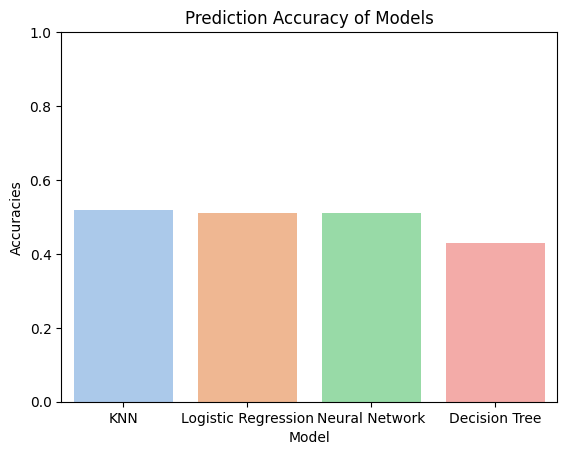

In [ ]:
sns.barplot(x='Model', y='Accuracies', data=a_df, palette='pastel')
pl.ylim(0,1)
pl.title('Prediction Accuracy of Models')
pl.show()

###Model Evaluation - Precision, Recall, F1 Score

In [ ]:
precisions = [
    precision_score(y_test, y_pred1, average='macro'),
    precision_score(y_test, y_pred2, average='macro'),
    precision_score(y_test, y_pred3, average='macro'),
    precision_score(y_test, y_pred4, average='macro')
]

recalls = [
    recall_score(y_test, y_pred1, average='macro'),
    recall_score(y_test, y_pred2, average='macro'),
    recall_score(y_test, y_pred3, average='macro'),
    recall_score(y_test, y_pred4, average='macro')
]

f1_scores = [
    f1_score(y_test, y_pred1, average='macro'),
    f1_score(y_test, y_pred2, average='macro'),
    f1_score(y_test, y_pred3, average='macro'),
    f1_score(y_test, y_pred4, average='macro')
]

model_names = ['KNN', 'Logistic Regression', 'Neural Network', 'Decision Tree']

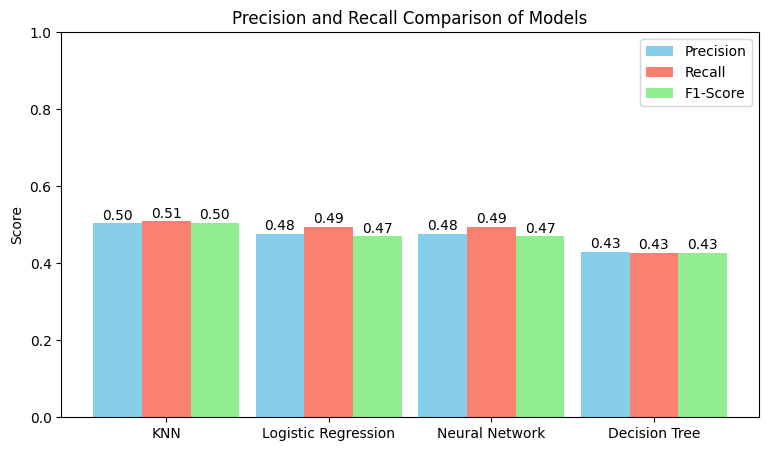

In [ ]:
x = np.arange(len(model_names))
width = 0.3

pl.figure(figsize=(9,5))
pl.bar(x - width, precisions, width, label='Precision', color='skyblue')
pl.bar(x, recalls, width, label='Recall', color='salmon')
pl.bar(x + width, f1_scores, width, label='F1-Score', color='lightgreen')

pl.xticks(x, model_names)
pl.ylim(0, 1)
pl.ylabel('Score')
pl.title('Precision and Recall Comparison of Models')
pl.legend()
for i in range(len(model_names)):
    pl.text(i - width, precisions[i] + 0.01, f"{precisions[i]:.2f}", ha='center')
    pl.text(i, recalls[i] + 0.01, f"{recalls[i]:.2f}", ha='center')
    pl.text(i + width, f1_scores[i] + 0.01, f"{f1_scores[i]:.2f}", ha='center')
pl.show()

###Model Evaluation - Confusion Matrix

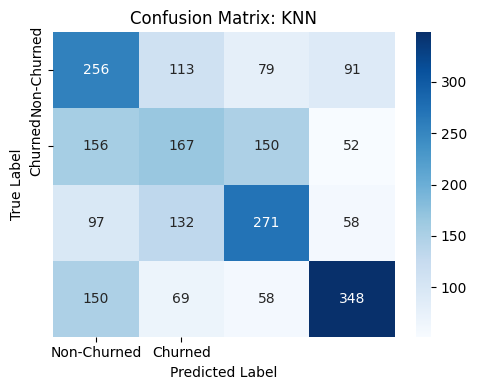

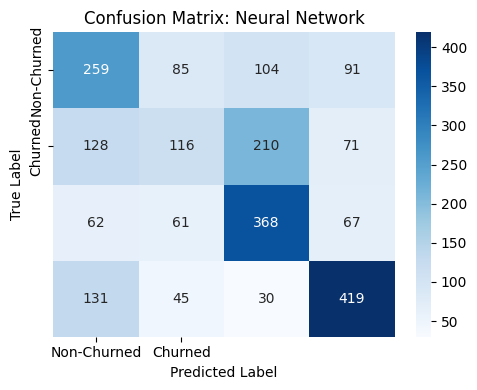

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


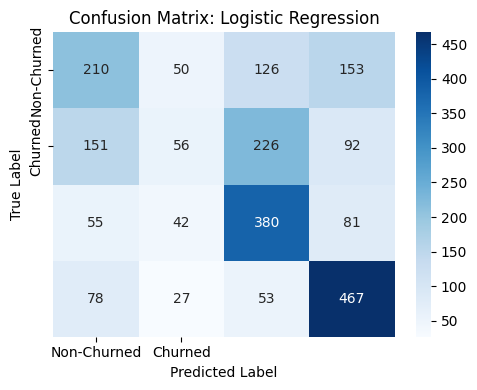

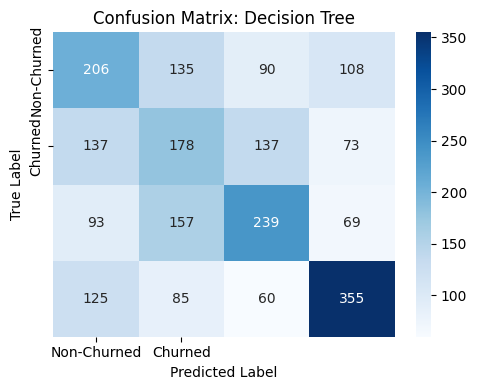

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    pl.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Churned', 'Churned'], yticklabels=['Non-Churned', 'Churned'])
    pl.title(f'Confusion Matrix: {name}')
    pl.xlabel('Predicted Label')
    pl.ylabel('True Label')
    pl.tight_layout()
    pl.show()

###Model Evaluation - ROC Curve, AUC Score

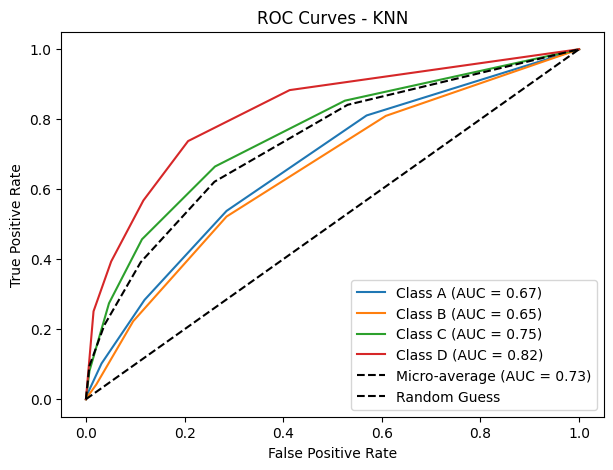

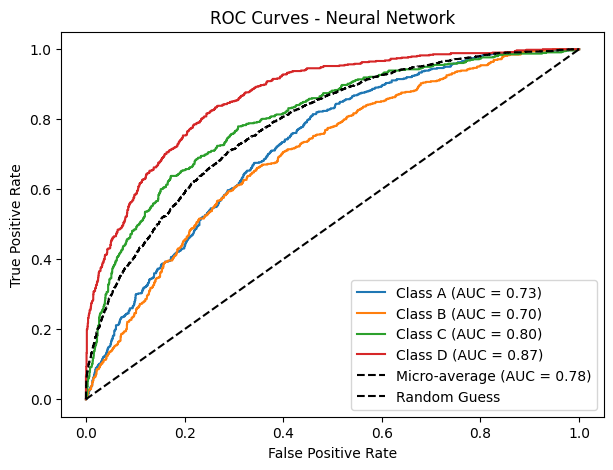

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


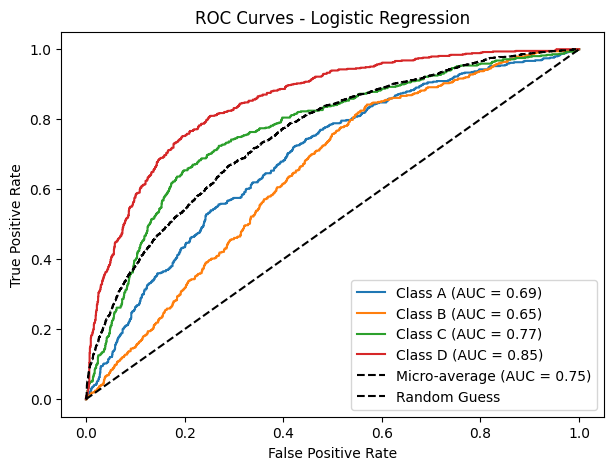

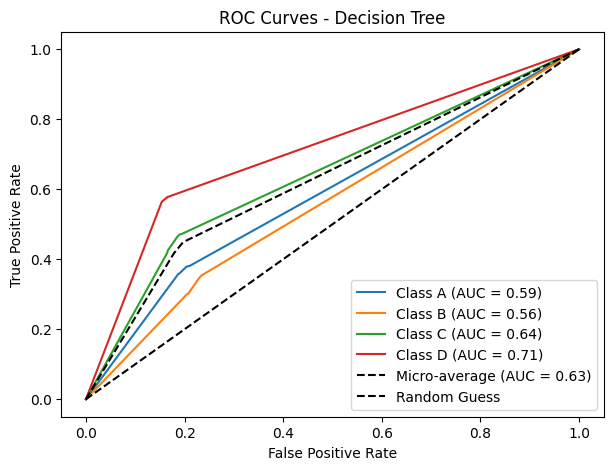

In [ ]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_probs = model.predict_proba(X_test_scaled)
    classes = np.unique(y_train)
    y_test_bin = label_binarize(y_test, classes=classes)
    pl.figure(figsize=(7, 5))

    # Per-class ROC
    for i, class_label in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        pl.plot(fpr, tpr, label=f"Class {class_label} (AUC = {roc_auc:.2f})")

    # Micro-average ROC
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_probs.ravel())
    roc_auc = auc(fpr, tpr)
    pl.plot(fpr, tpr, linestyle="--", color="black",
             label=f"Micro-average (AUC = {roc_auc:.2f})")

    pl.plot([0, 1], [0, 1], "k--", label="Random Guess")

    pl.title(f"ROC Curves - {name}")
    pl.xlabel("False Positive Rate")
    pl.ylabel("True Positive Rate")
    pl.legend()
    pl.show()

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was depre

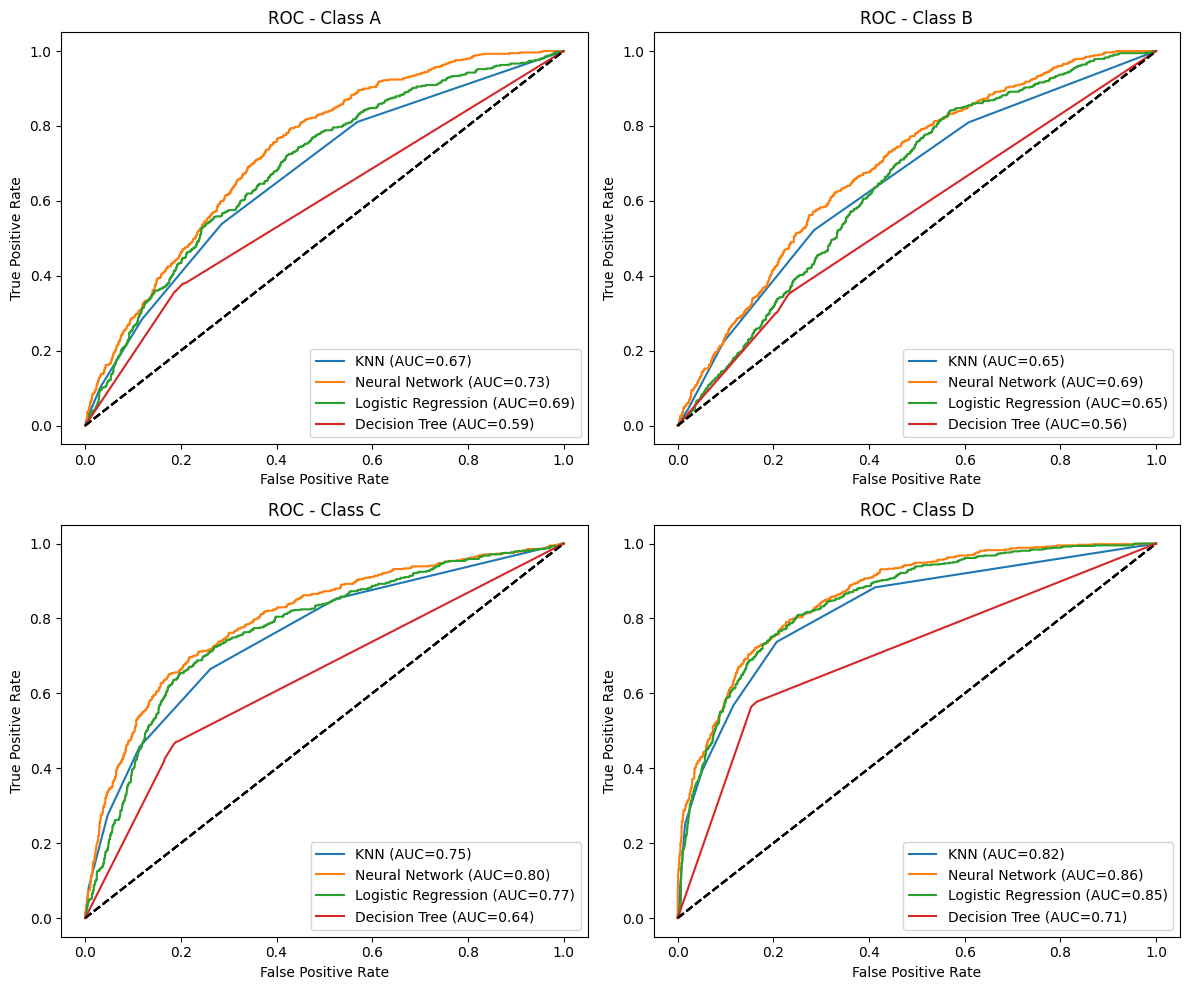

In [ ]:
fig, axes = pl.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, class_label in enumerate(classes):
  for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_probs = model.predict_proba(X_test_scaled)

    y_test_bin = label_binarize(y_test, classes=classes)
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)

    axes[i].plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.2f})")

    axes[i].plot([0, 1], [0, 1], "k--")
    axes[i].set_title(f"ROC - Class {class_label}")
    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].legend(loc='lower right')

pl.tight_layout()
pl.show()

###Unsupervised Learning - K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
feature_names = dataset.columns.tolist()
df7 = pd.DataFrame(df6, columns=feature_names[1:len(feature_names)-1])

In [ ]:
X = df7.values

kmeans = KMeans(n_clusters=4)
df7["cluster"] = kmeans.fit_predict(X)

In [ ]:
print(df7["cluster"])

0       0
1       3
2       1
3       1
4       3
       ..
8063    0
8064    3
8065    0
8066    0
8067    3
Name: cluster, Length: 7487, dtype: int32


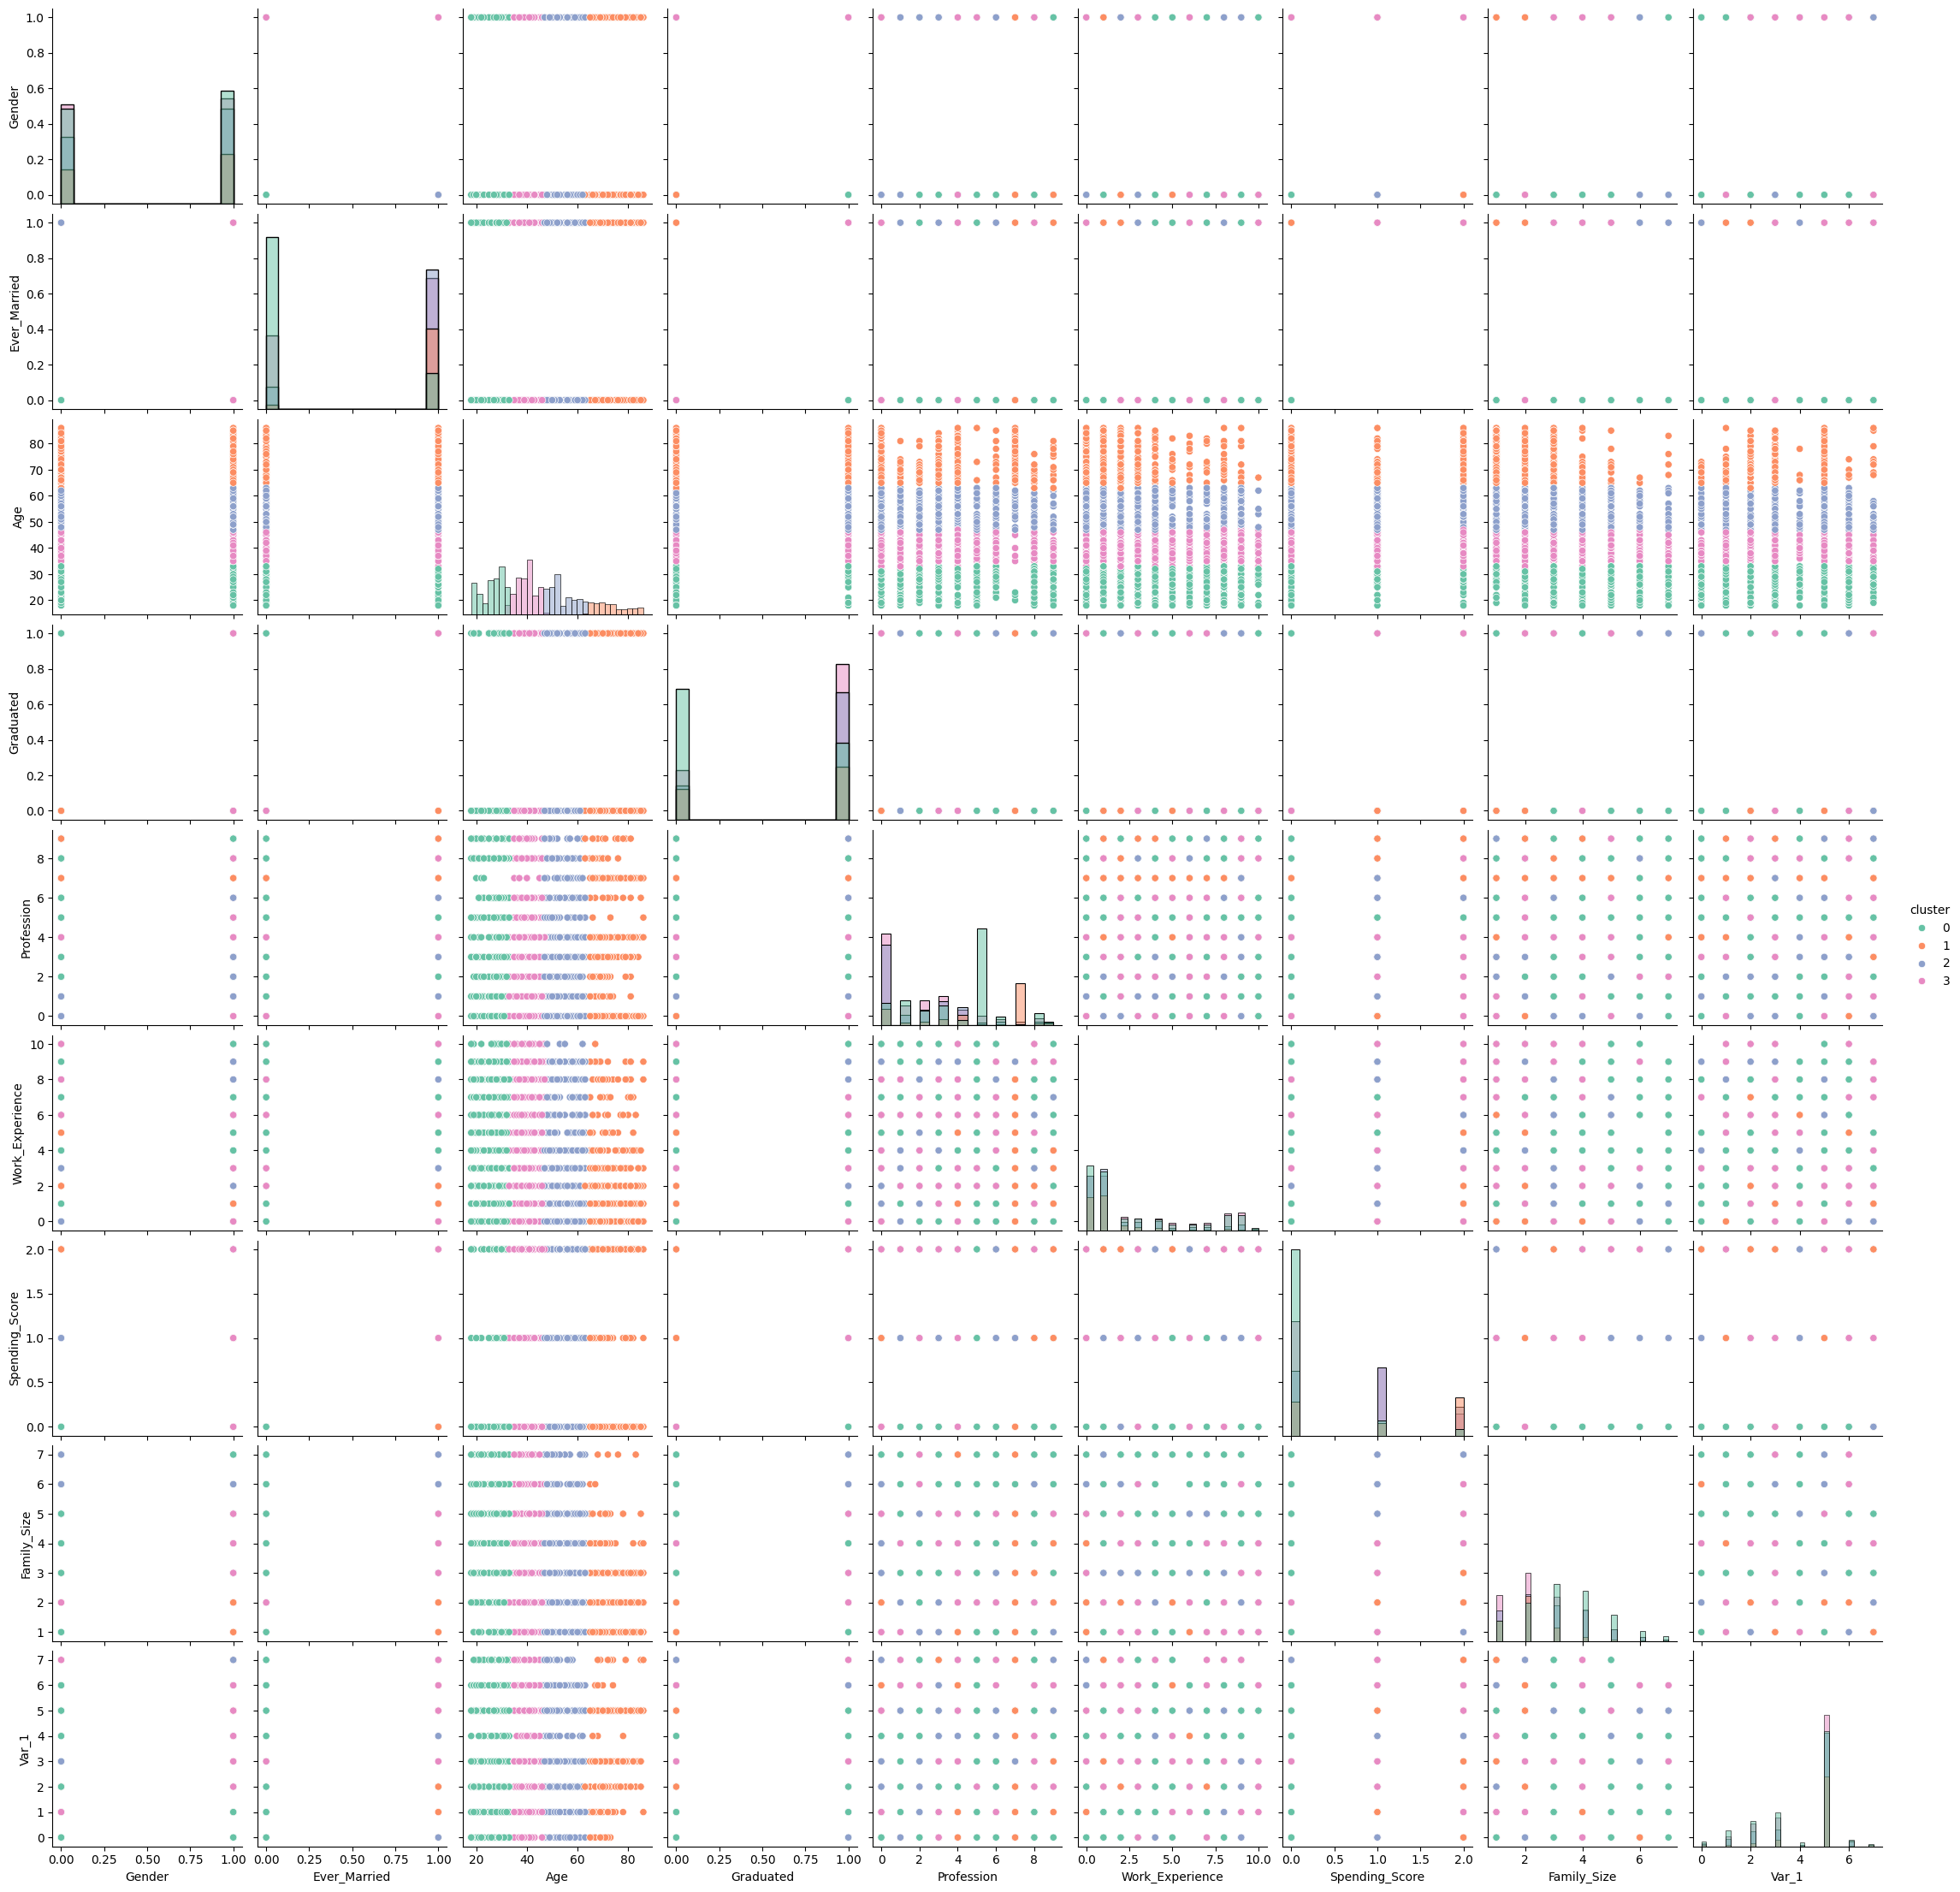

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df7, hue="cluster", diag_kind="hist", palette="Set2")
plt.show()

1


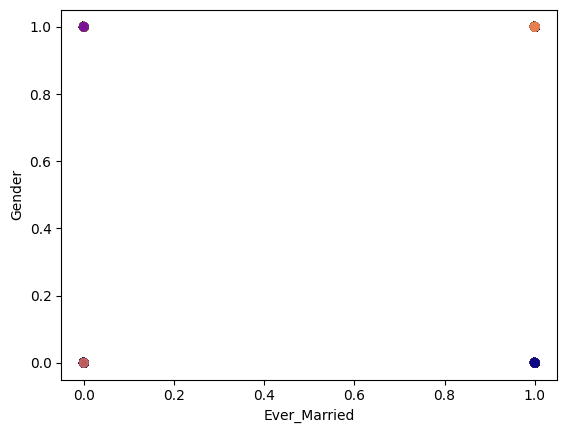

2


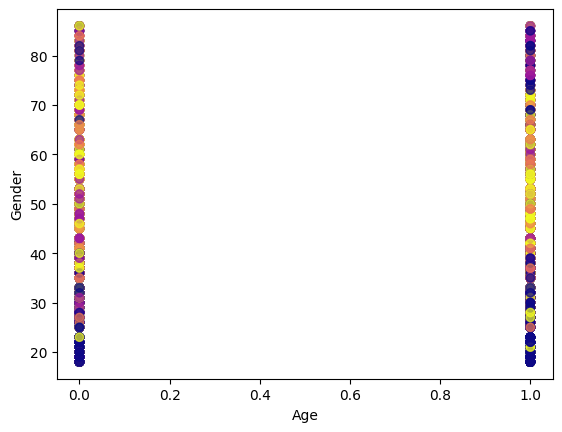

3


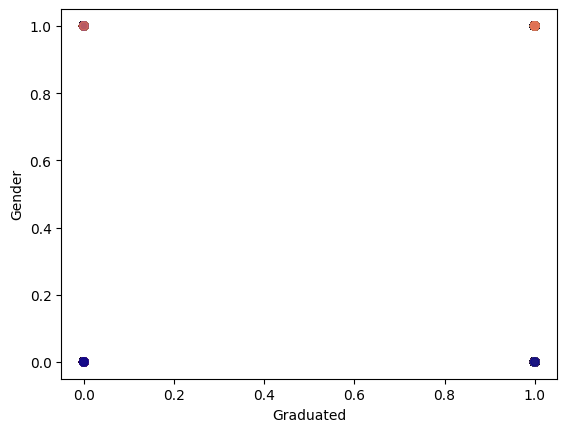

4


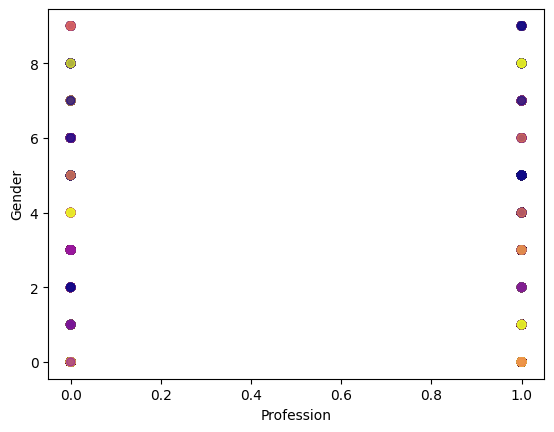

5


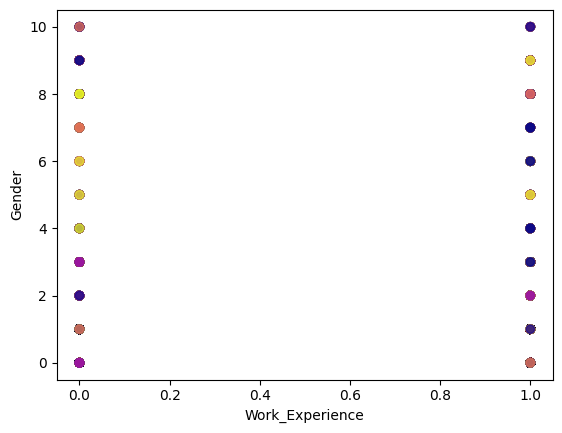

6


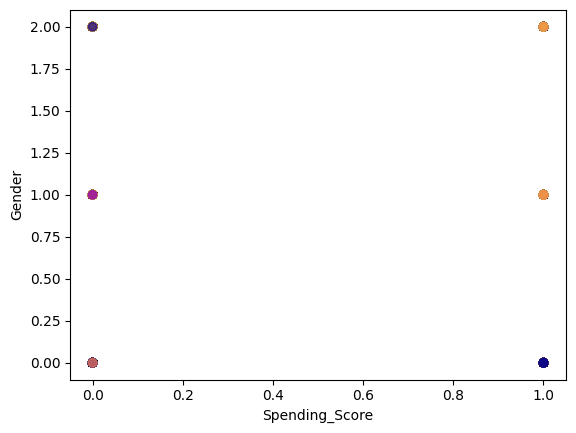

7


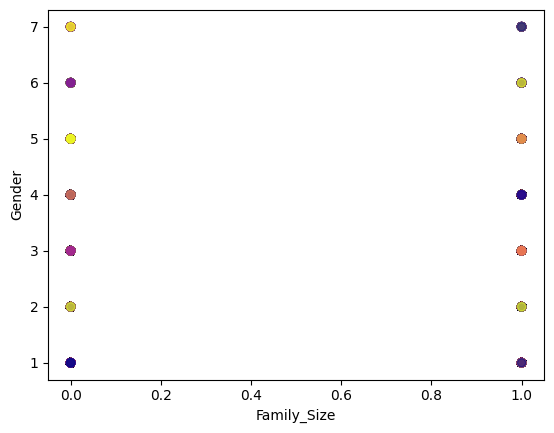

8


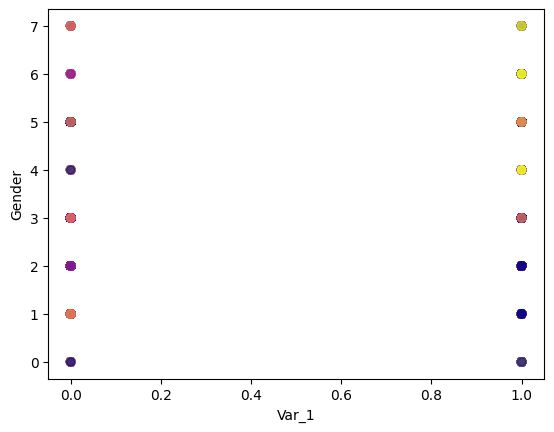

9


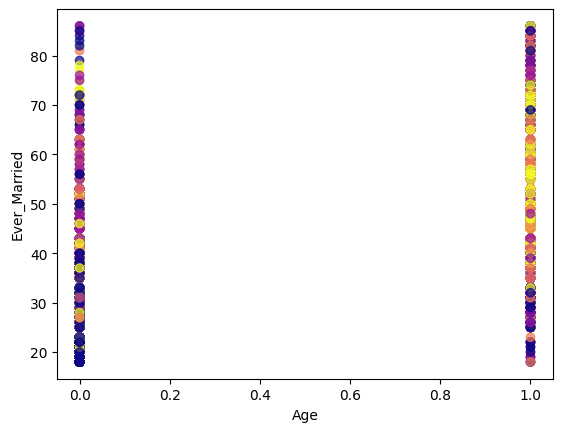

10


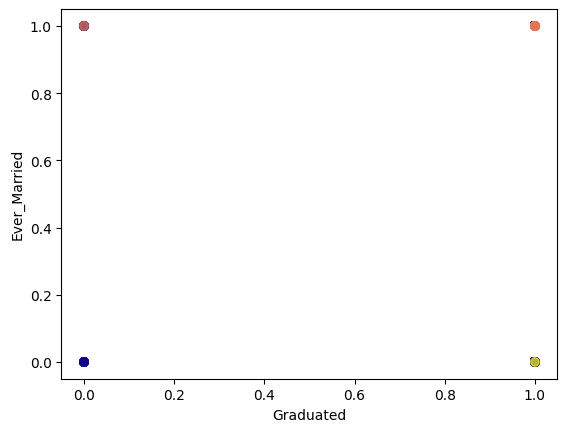

11


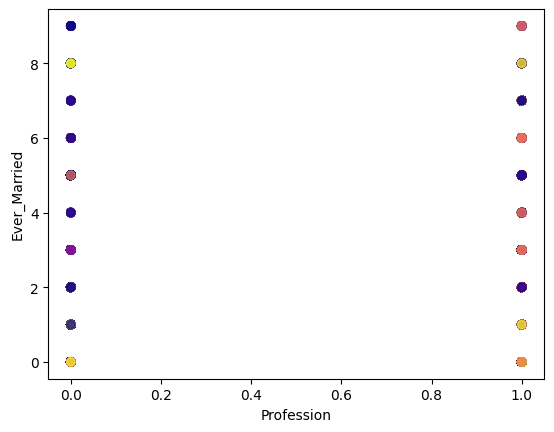

12


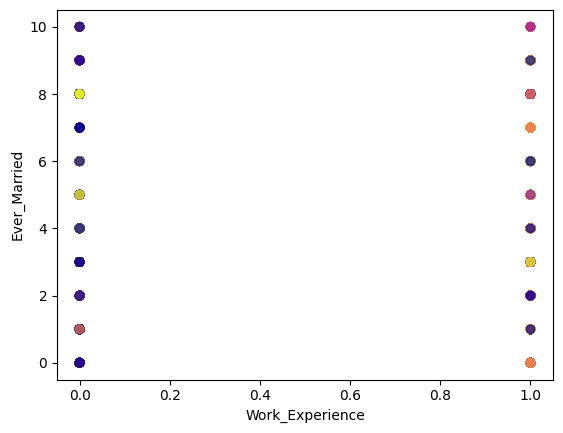

13


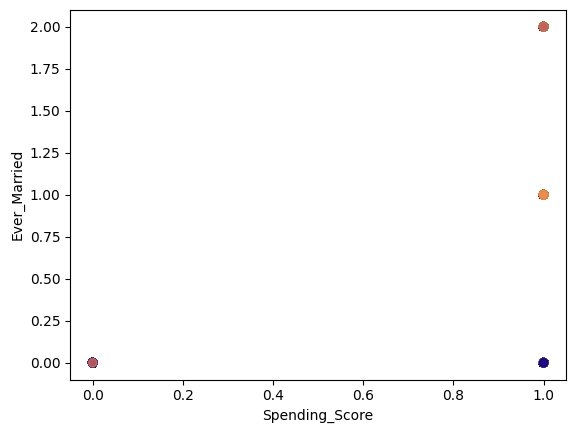

14


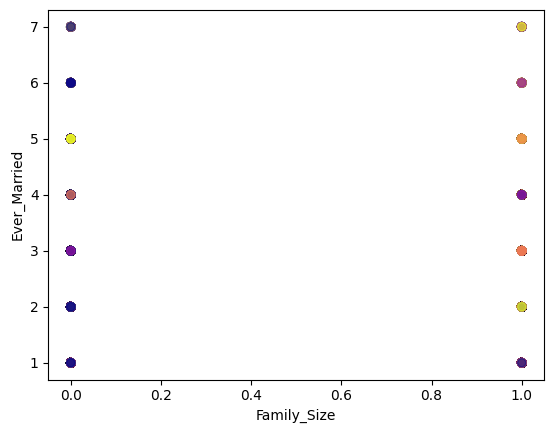

15


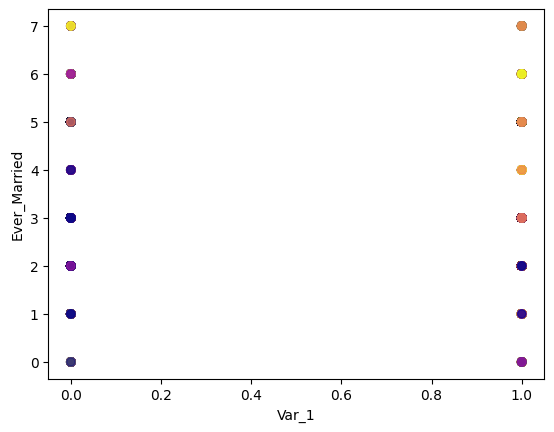

16


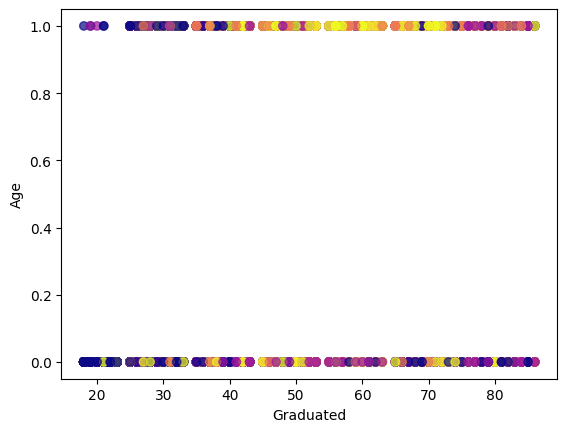

17


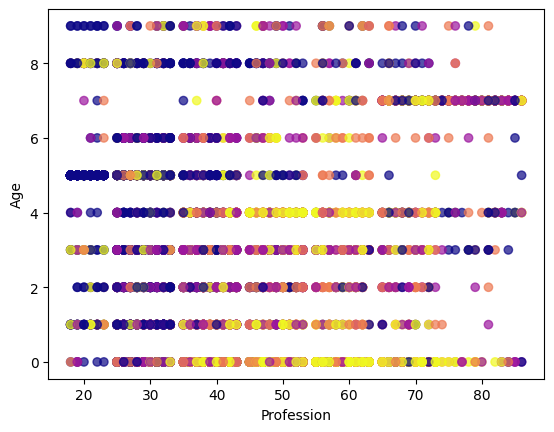

18


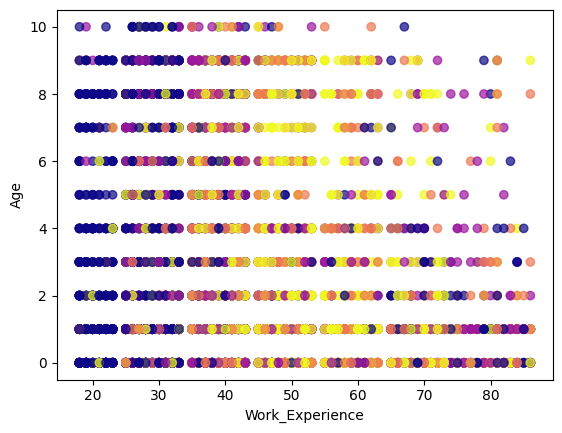

19


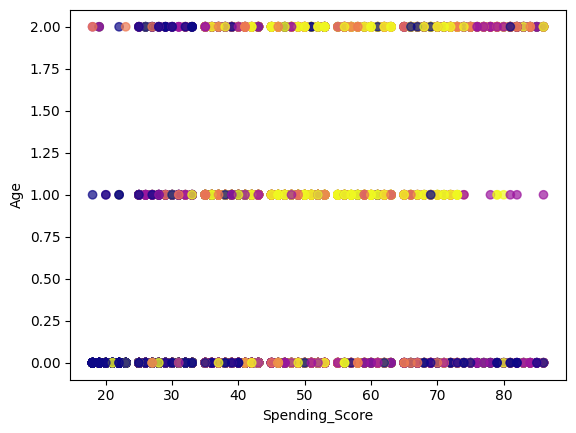

20


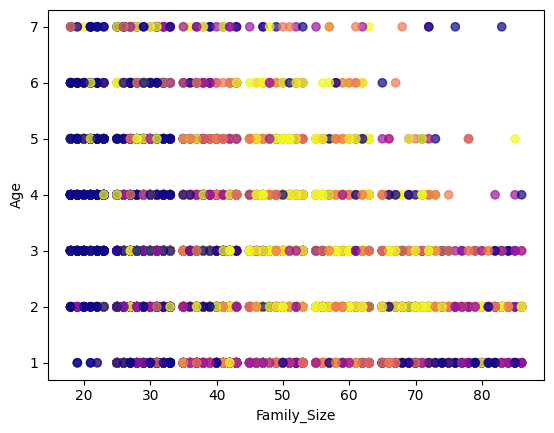

21


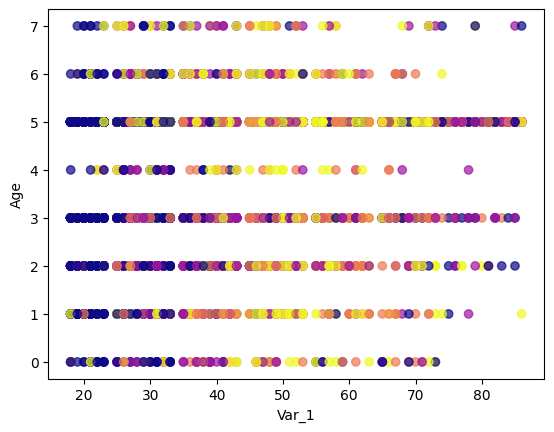

22


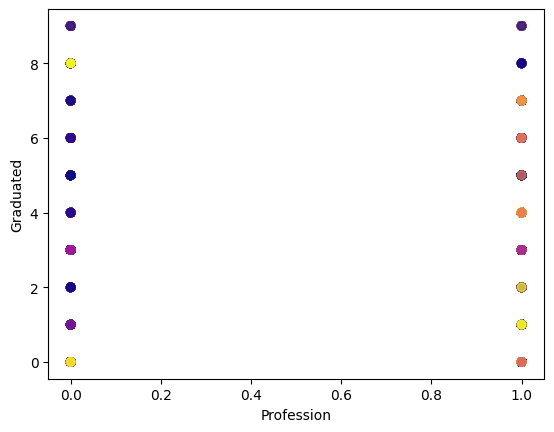

23


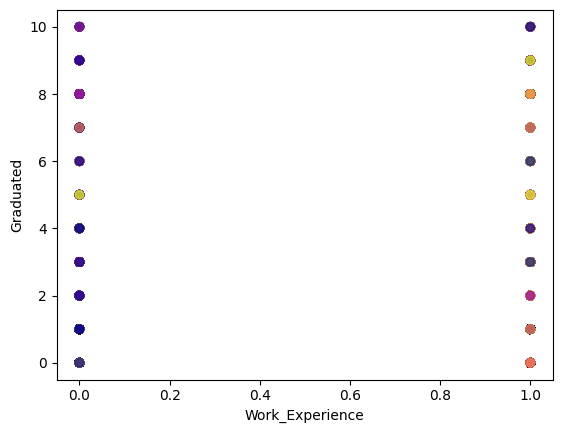

24


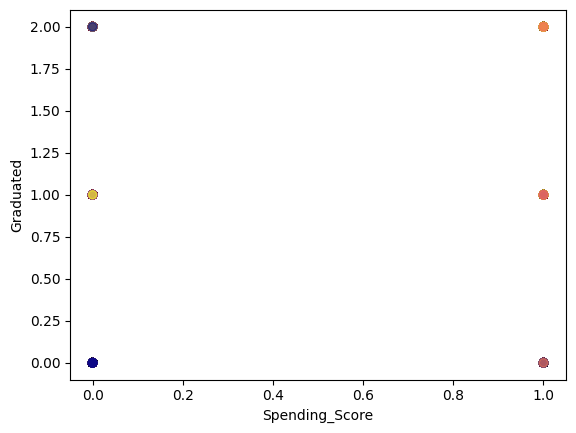

25


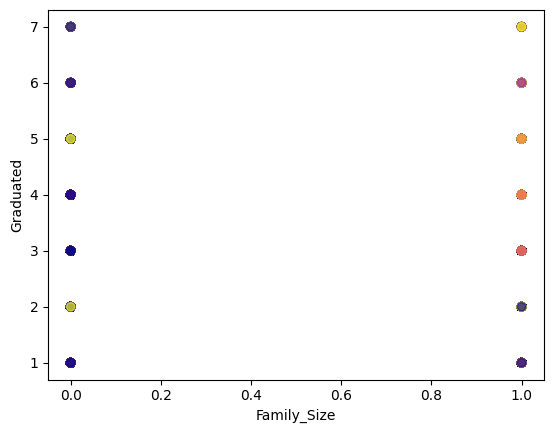

26


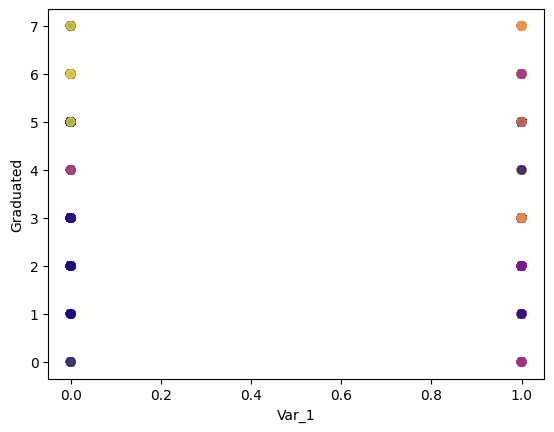

27


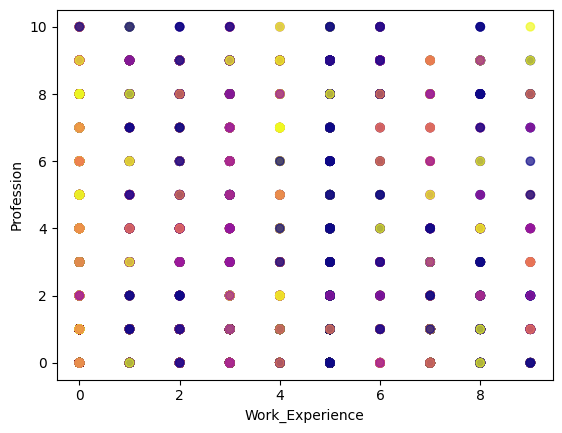

28


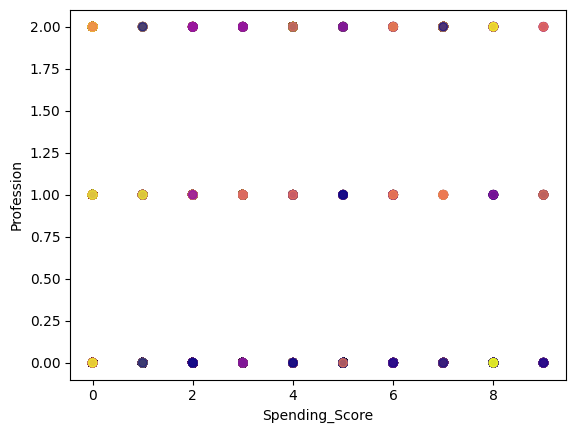

29


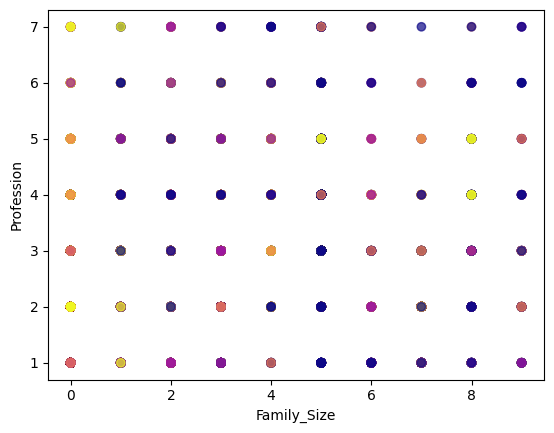

30


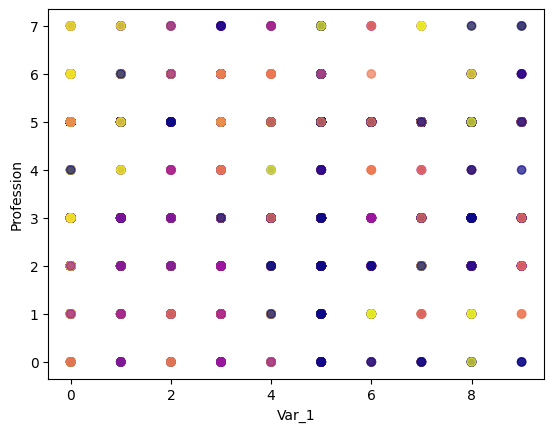

31


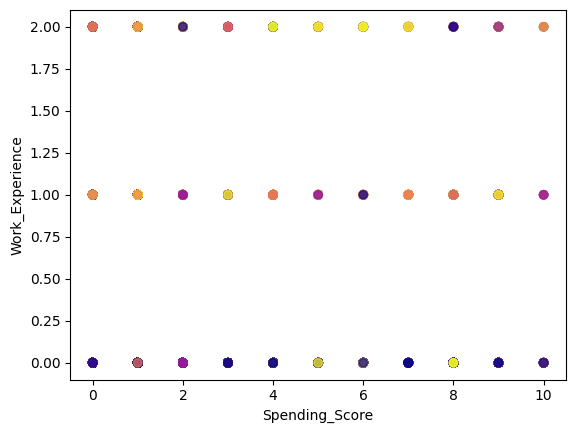

32


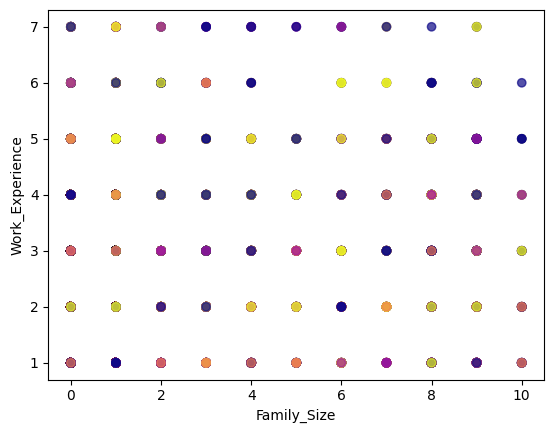

33


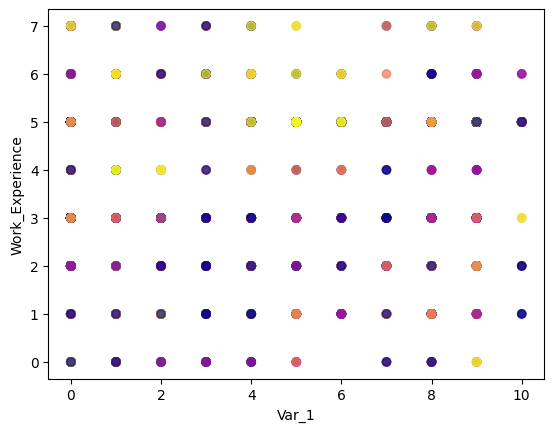

34


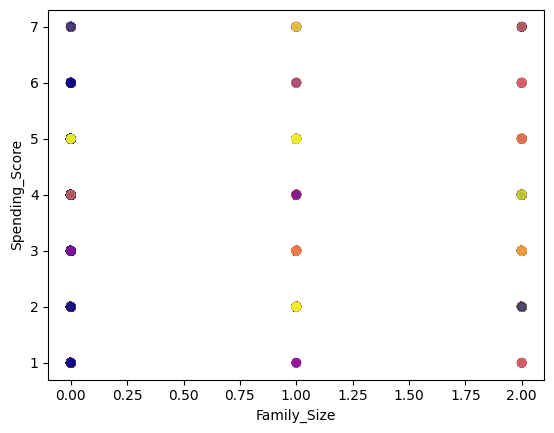

35


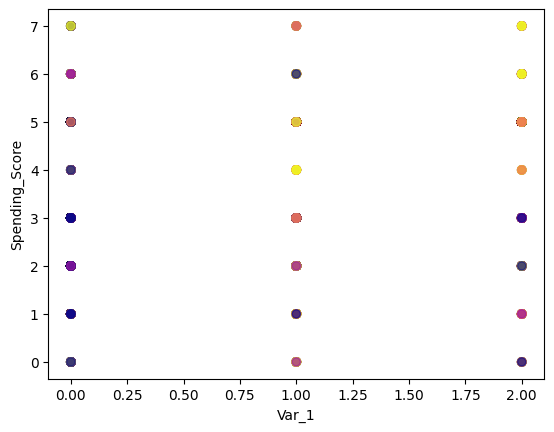

36


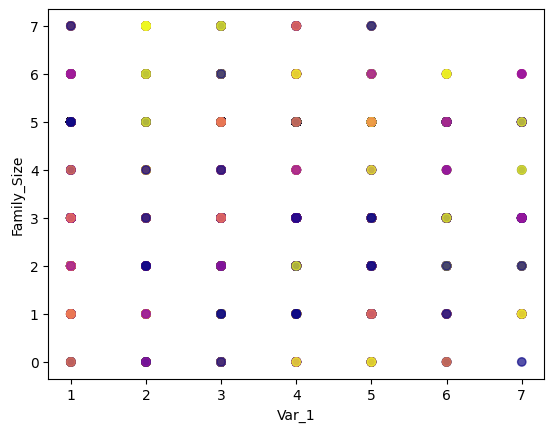

In [ ]:
count = 0
colors, uniques = pd.factorize(df5["Segmentation"])
for i in range(1, len(feature_names)-1):
  for j in range(i+1, len(feature_names)-1):
    if i != j:
      count+=1
      print(count)
      plt.figure()
      plt.ylabel(feature_names[i])
      plt.xlabel(feature_names[j])
      plt.scatter(
          df5[feature_names[i]],
          df5[feature_names[j]],
          c=colors,
          cmap='plasma',
          alpha=0.7
      )
      plt.show()

In [ ]:
# 9*9 scatter plot, 81 plots,
# diagonal plots 9, 81-9=72
# symmetric upper and lower triangular plots, 72/2=36
# 36 plots

**No corelation among the features**

**Not possible to cluster in 4 "Segmentation" groups**